# Routing quality and compilation time comparison

Circuit-quality metrics and compilation timings are collected by separate helper functions and saved to separate JSON files. This keeps SWAP and gate-count work out of timing measurements. SWAP counts use custom_routed_circuit; two-qubit gate counts, depths, and routing plus optimization times use final_optimized_circuit.

Circuit plots show means with standard-deviation bands. Timing plots show medians.


## Imports and backend


In [133]:
import importlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
import helper_functions as _helper_functions

importlib.reload(_helper_functions)
return_ops_all_methods = _helper_functions.return_ops_all_methods
return_times_all_methods = _helper_functions.return_times_all_methods

backend = FakeMarrakesh()
print(f'Backend: {backend.name}; physical qubits: {backend.num_qubits}')


Backend: fake_marrakesh; physical qubits: 156


## Experiment configuration


In [134]:
nodes_reg = list(range(10, 151, 2))
params_reg = list(range(3, 9))
nodes_ba = list(range(10, 151, 2))
params_ba = list(range(2, 5))

quality_k_list = [2, 3, 4]  # SAM2, SAM3, SAM4
timing_k_list = [4]         # timings requested for SAM4
opt_levels = [1, 2, 3]
average_over = 10
reps = 1
noise_aware = True
FORCE_RECOMPUTE = False


## Separate circuit-quality and timing runs


In [135]:
_results_dir = Path.cwd()
if not (_results_dir / 'helper_functions.py').is_file() and (_results_dir / 'submissions' / 'helper_functions.py').is_file():
    _results_dir = _results_dir / 'submissions'

OPS_RESULTS_FILE = _results_dir / 'comparison_unified_ops_results_v1.json'
TIMING_RESULTS_FILE = _results_dir / 'comparison_unified_times_results_v1.json'

quality_methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in quality_k_list]
timing_methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in timing_k_list]
graph_cases = {
    **{f'rr_d{d}': ('reg', d, nodes_reg, f'Random regular, d={d}') for d in params_reg},
    **{f'ba_m{m}': ('ba', m, nodes_ba, f'Barabasi-Albert, m={m}') for m in params_ba},
}
common_config = {
    'backend': str(backend.name),
    'average_over': int(average_over),
    'reps': int(reps),
    'noise_aware': bool(noise_aware),
    'nodes_reg': list(nodes_reg),
    'params_reg': list(params_reg),
    'nodes_ba': list(nodes_ba),
    'params_ba': list(params_ba),
}
ops_config = {
    **common_config,
    'schema_version': 1,
    'quality_k_list': list(quality_k_list),
    'opt_levels': list(opt_levels),
}
timing_config = {
    **common_config,
    'schema_version': 1,
    'timing_k_list': list(timing_k_list),
    'opt_levels': list(opt_levels),
}


def load_results(path, config, reset=False):
    if path.exists() and not reset:
        saved = json.loads(path.read_text(encoding='utf-8'))
        if saved.get('configuration') != config:
            raise ValueError(
                f'{path.name} has a different configuration. '
                'Set FORCE_RECOMPUTE = True to replace it.'
            )
        return saved.get('results', {'cases': {}})
    return {'cases': {}}


def save_results(path, config, results):
    payload = {'configuration': config, 'results': results}
    path.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding='utf-8')


### Collect timing values separately


In [136]:
timing_results = load_results(TIMING_RESULTS_FILE, timing_config, reset=FORCE_RECOMPUTE)
for case_key, (graph_type, graph_param, node_sizes, graph_label) in graph_cases.items():
    if case_key not in timing_results['cases']:
        print(f'Timing-only run: {graph_label}')
        timing_results['cases'][case_key] = return_times_all_methods(
            backend,
            graph_type=graph_type,
            param=graph_param,
            average_over=average_over,
            node_list=node_sizes,
            k_list=timing_k_list,
            reps=reps,
            opt_levels=opt_levels,
            noise_aware=noise_aware,
        )
        save_results(TIMING_RESULTS_FILE, timing_config, timing_results)

del timing_results
print(f'Timing summaries are saved in {TIMING_RESULTS_FILE}')


Timing summaries are saved in c:\Users\devra\Projects\Qubit Routing\submissions\comparison_unified_times_results_v1.json


### Collect circuit-quality values


In [137]:
ops_results = load_results(OPS_RESULTS_FILE, ops_config, reset=FORCE_RECOMPUTE)
for case_key, (graph_type, graph_param, node_sizes, graph_label) in graph_cases.items():
    if case_key not in ops_results['cases']:
        print(f'Circuit-quality run: {graph_label}')
        ops_results['cases'][case_key] = return_ops_all_methods(
            backend,
            graph_type=graph_type,
            param=graph_param,
            average_over=average_over,
            node_list=node_sizes,
            k_list=quality_k_list,
            reps=reps,
            opt_levels=opt_levels,
            noise_aware=noise_aware,
        )
        save_results(OPS_RESULTS_FILE, ops_config, ops_results)

del ops_results
print(f'Circuit-quality summaries are saved in {OPS_RESULTS_FILE}')


Circuit-quality summaries are saved in c:\Users\devra\Projects\Qubit Routing\submissions\comparison_unified_ops_results_v1.json


## Plot helpers


In [ ]:
quality_results = load_results(OPS_RESULTS_FILE, ops_config)
timing_results = load_results(TIMING_RESULTS_FILE, timing_config)
quality_colors = {
    'SABRE': '#E69F00',
    'Trivial': '#56B4E9',
    'FOM': '#009E73',
    'SAM2': '#0072B2',
    'SAM3': '#D55E00',
    'SAM4': '#CC79A7',
}
timing_colors = {method: quality_colors[method] for method in timing_methods}
level_styles = {1: '-', 2: '--', 3: ':'}


def _plot_quality_by_parameter(graph_family, metric, levels, plot_title):
    """Plot means with standard-deviation bands, one figure per parameter."""
    family = 'rr' if graph_family == 'reg' else 'ba'
    parameters = params_reg if graph_family == 'reg' else params_ba
    node_sizes = nodes_reg if graph_family == 'reg' else nodes_ba
    is_shared_metric = metric == 'swaps'
    plotted_levels = [None] if is_shared_metric else levels

    for param in parameters:
        fig, ax = plt.subplots(figsize=(9, 6))
        case_key = f'{family}_d{param}' if graph_family == 'reg' else f'{family}_m{param}'
        case_quality = quality_results['cases'][case_key]
        for method in quality_methods:
            for level in plotted_levels:
                stats = case_quality[metric] if level is None else case_quality[metric][str(level)]
                means = np.asarray(stats['means'][method], dtype=float)
                stddevs = np.asarray(stats['stddevs'][method], dtype=float)
                linestyle = '-'
                ax.plot(
                    node_sizes, means, color=quality_colors[method],
                    linestyle=linestyle,
                    linewidth=1.8,
                )
                ax.fill_between(
                    node_sizes, np.maximum(0.0, means - stddevs), means + stddevs,
                    color=quality_colors[method], alpha=0.25,
                )

        handles = [
            Line2D([0], [0], color=quality_colors[method], linewidth=2, label=method)
            for method in quality_methods
        ]
        if len(plotted_levels) > 1:
            handles += [
                Line2D(
                    [0], [0], color='black', linestyle=level_styles[level],
                    label=f'Opt level {level}',
                )
                for level in plotted_levels
            ]
        ylabel = 'SWAPs' if metric == 'swaps' else metric.replace('_', ' ').title()
        # ax.set_title(f'{graph_family.upper()}, parameter = {param}: {plot_title}')
        ax.set_xlabel('Number of nodes', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.25)
        ax.legend(handles=handles, loc='best', ncol=2, fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=14)
        fig.tight_layout()
        plt.savefig(f'comparison/{graph_family}{param}_{metric}{"lvl_" + str(levels[0]) if levels else ""}.png', dpi=300)
        plt.show()


def _plot_timing_by_parameter(graph_family, plot_title, stage_specs, metric):
    """Plot timing medians only, one figure per parameter."""
    family = 'rr' if graph_family == 'reg' else 'ba'
    parameters = params_reg if graph_family == 'reg' else params_ba
    node_sizes = nodes_reg if graph_family == 'reg' else nodes_ba

    for param in parameters:
        fig, ax = plt.subplots(figsize=(9, 6))
        case_key = f'{family}_d{param}' if graph_family == 'reg' else f'{family}_m{param}'
        case_timing = timing_results['cases'][case_key]
        for method in timing_methods:
            for stage, level, linestyle, _label in stage_specs:
                stats = case_timing[stage]
                if level is not None:
                    stats = stats[str(level)]
                median = np.asarray(stats['medians'][method], dtype=float)
                ax.plot(
                    node_sizes, median, color=timing_colors[method],
                    linestyle=linestyle,
                    linewidth=1.8,
                )

        handles = [
            Line2D([0], [0], color=timing_colors[method], linewidth=2, label=method)
            for method in timing_methods
        ]
        handles += [
            Line2D(
                [0], [0], color='black', linestyle=linestyle,
                label=label,
            )
            for _stage, _level, linestyle, label in stage_specs
        ]
        # ax.set_title(f'{graph_family.upper()}, parameter = {param}: {plot_title}')
        ax.set_xlabel('Number of nodes', fontsize=18)
        ax.set_ylabel('Time (seconds)', fontsize=18)
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.25)
        ax.legend(handles=handles, loc='best', ncol=2, fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=14)
        fig.tight_layout()
        plt.savefig(f'comparison/{graph_family}{param}_time{metric}.png', dpi=300)
        plt.show()


## Random-regular graphs


### 1. Number of nodes vs mean routed SWAP count


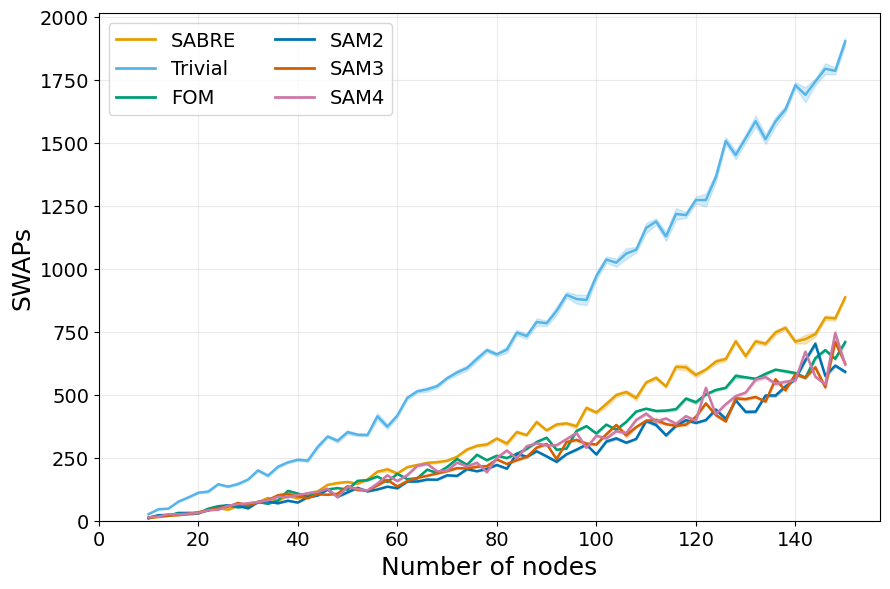

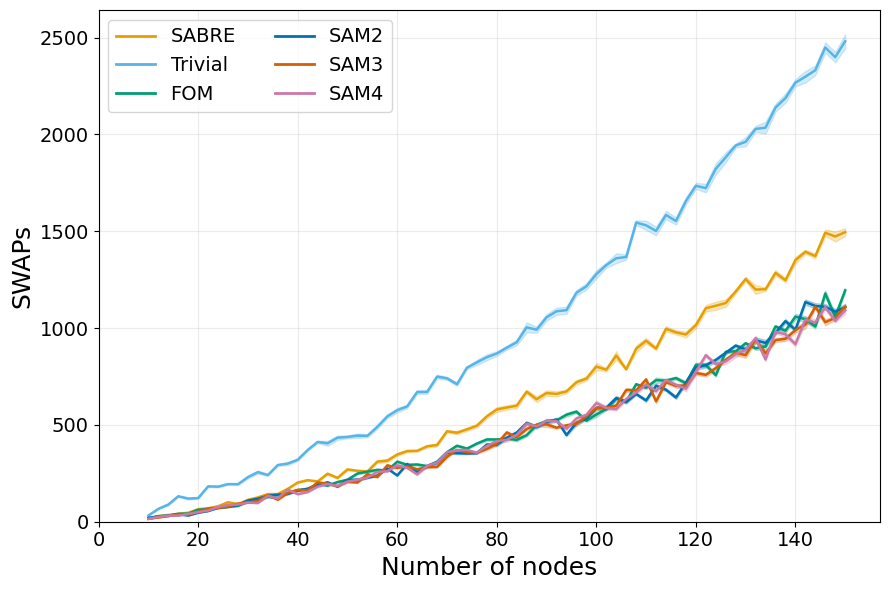

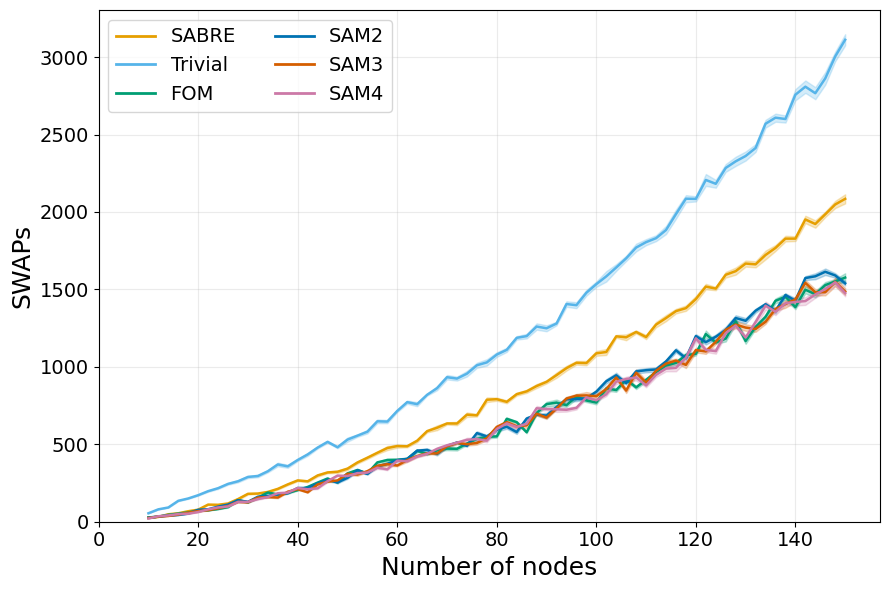

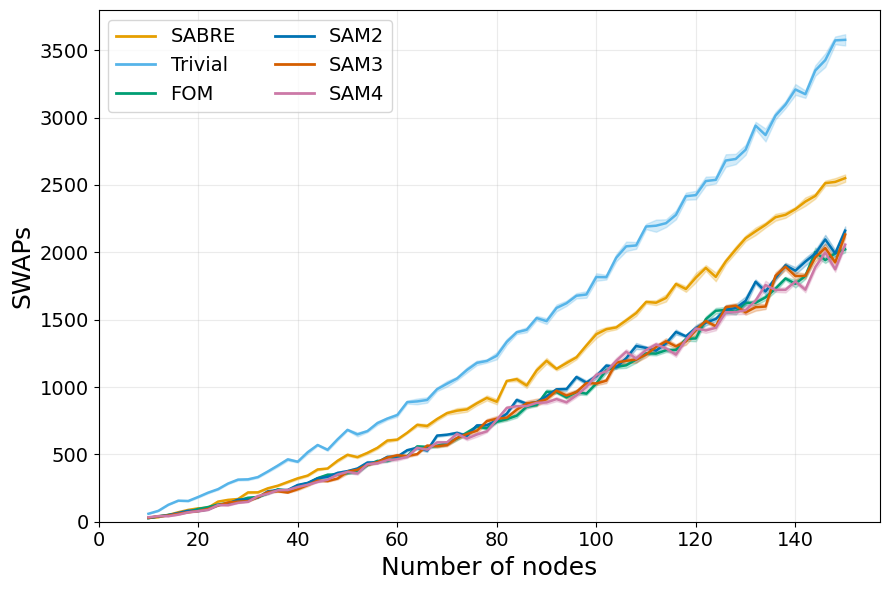

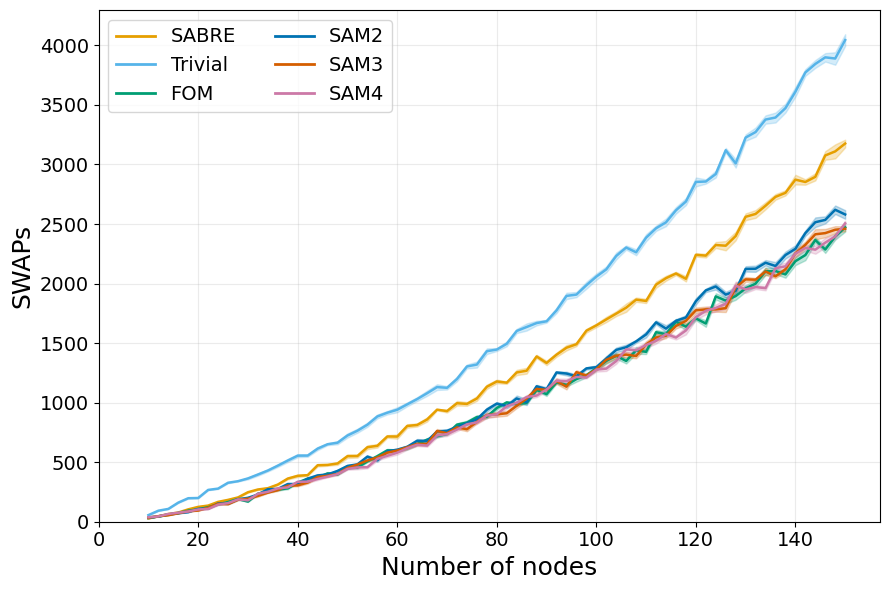

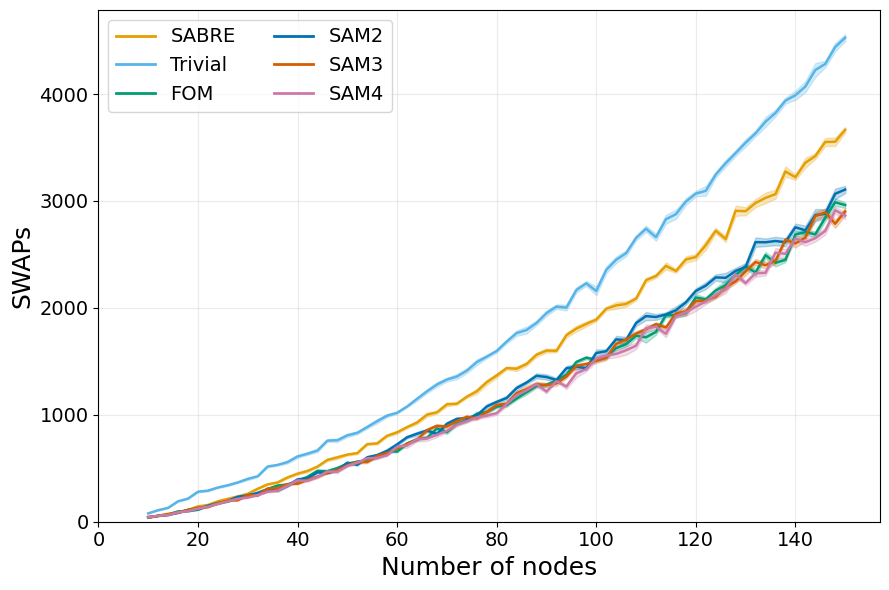

In [139]:
_plot_quality_by_parameter('reg', 'swaps', [], 'Mean routed SWAP count')


### 2. Number of nodes vs mean two-qubit gate count, optimization level 1


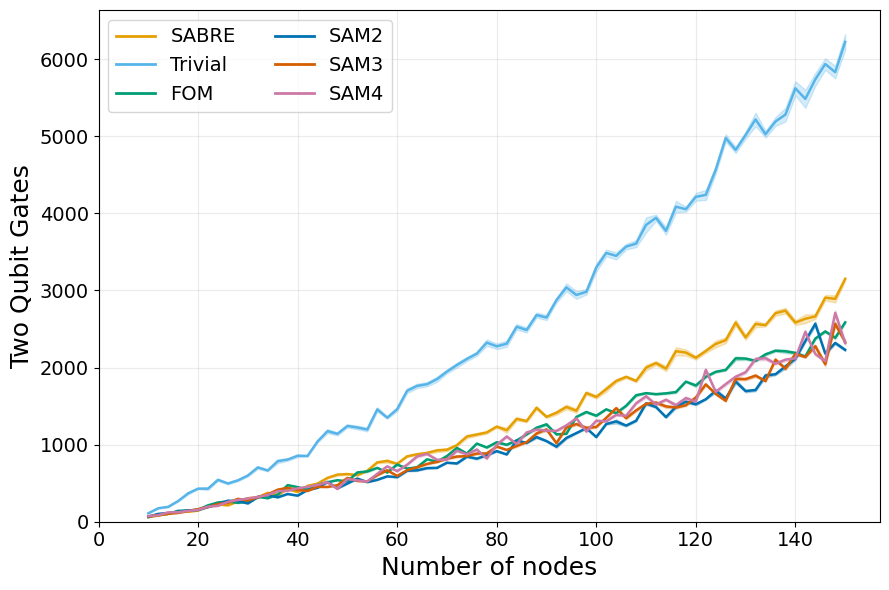

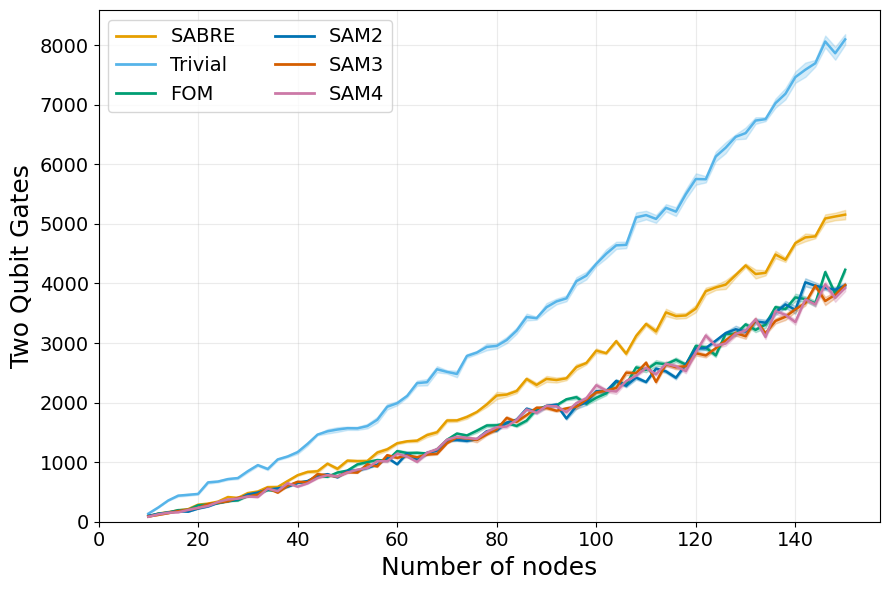

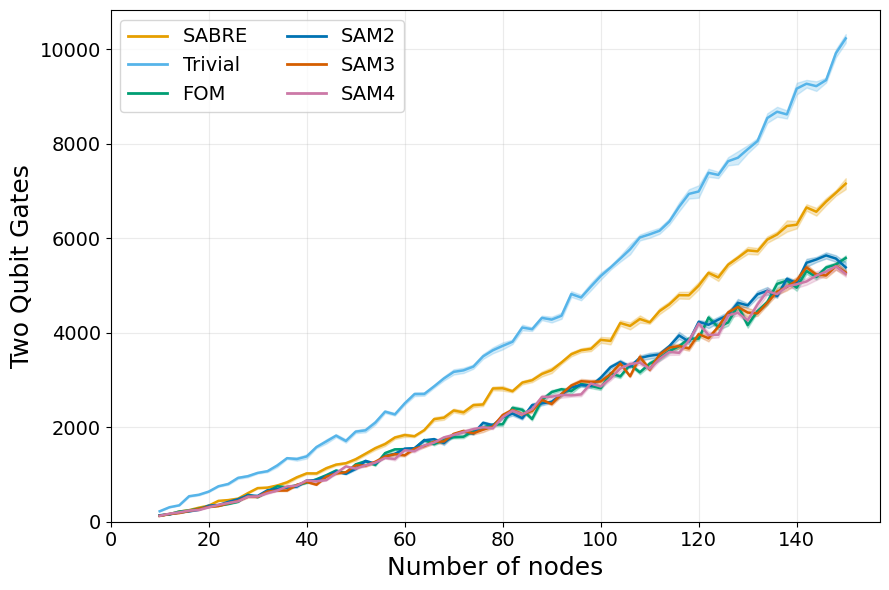

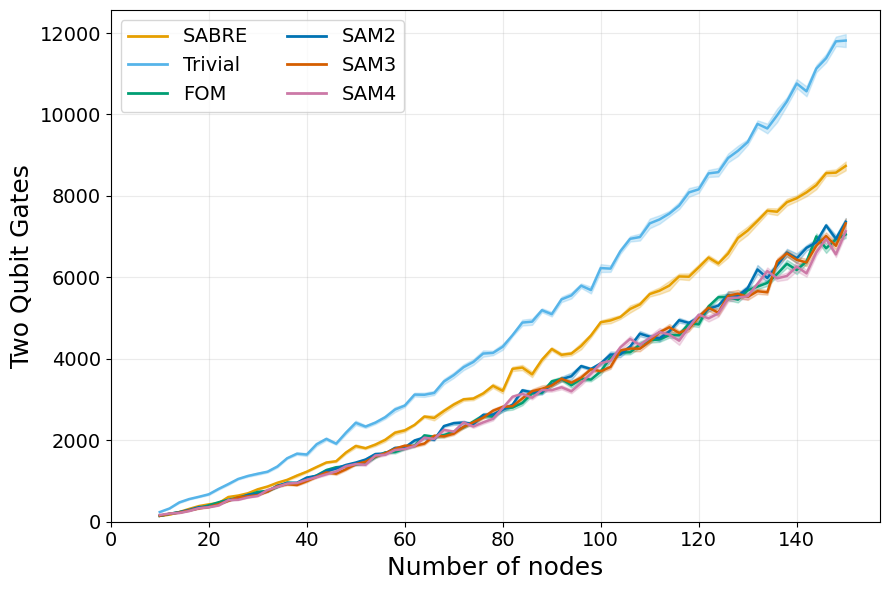

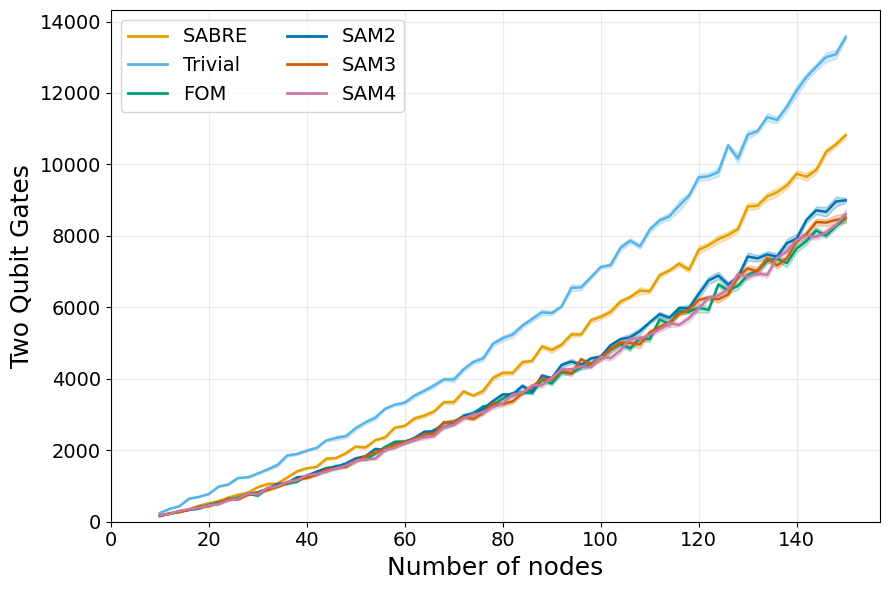

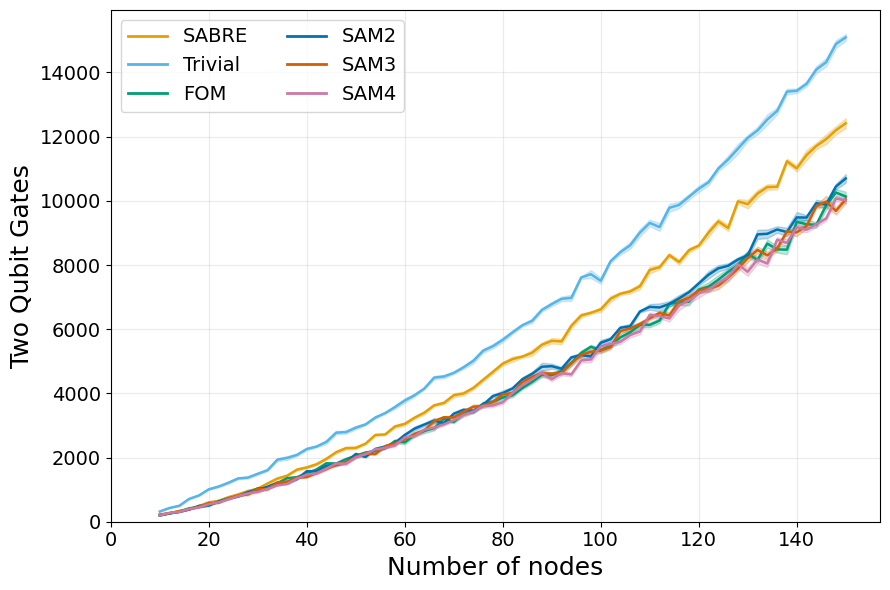

In [140]:
_plot_quality_by_parameter('reg', 'two_qubit_gates', [1], 'Mean two-qubit gates, opt level 1')


### 3. Number of nodes vs mean two-qubit gate count, optimization level 2


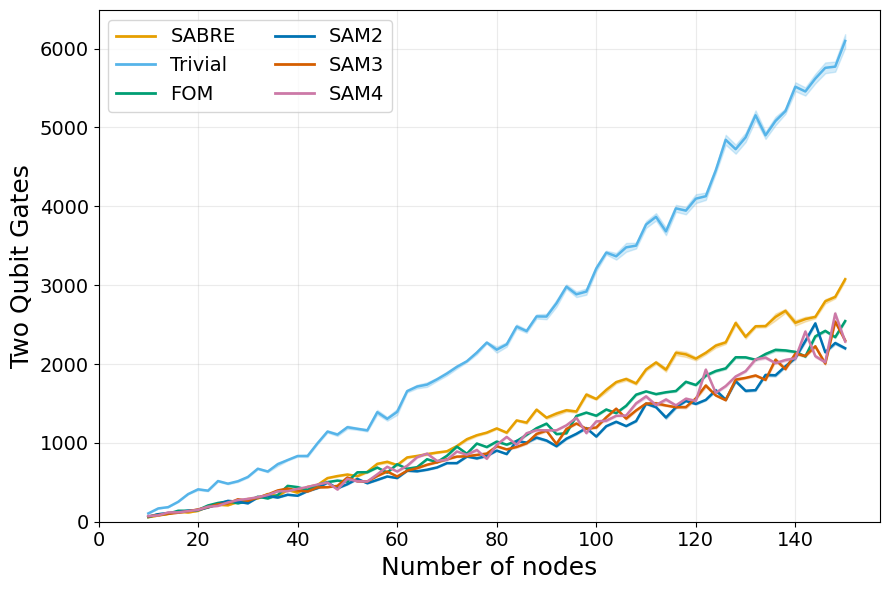

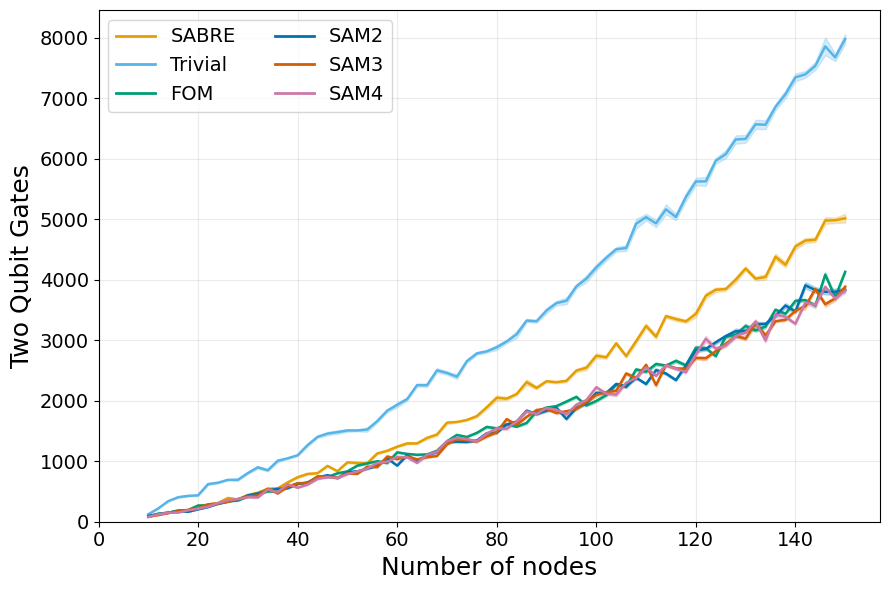

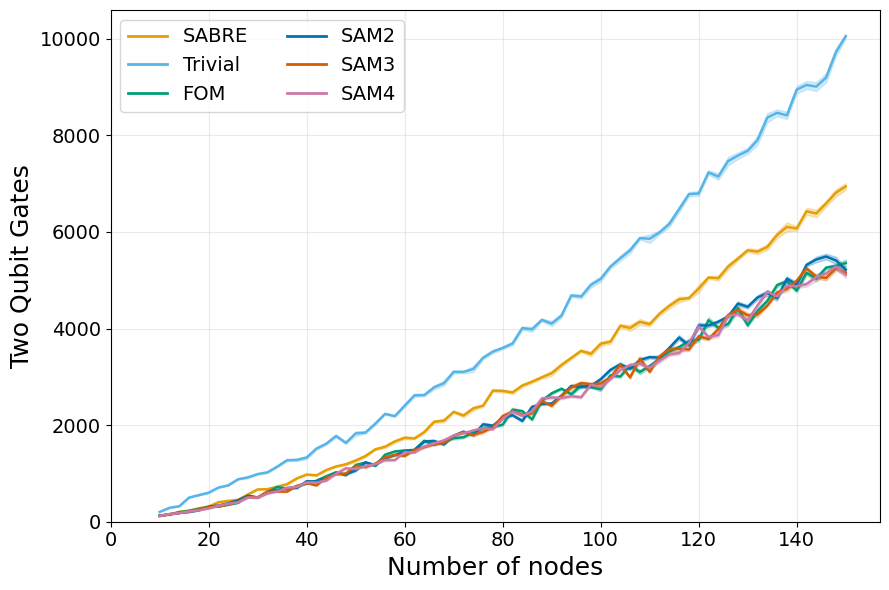

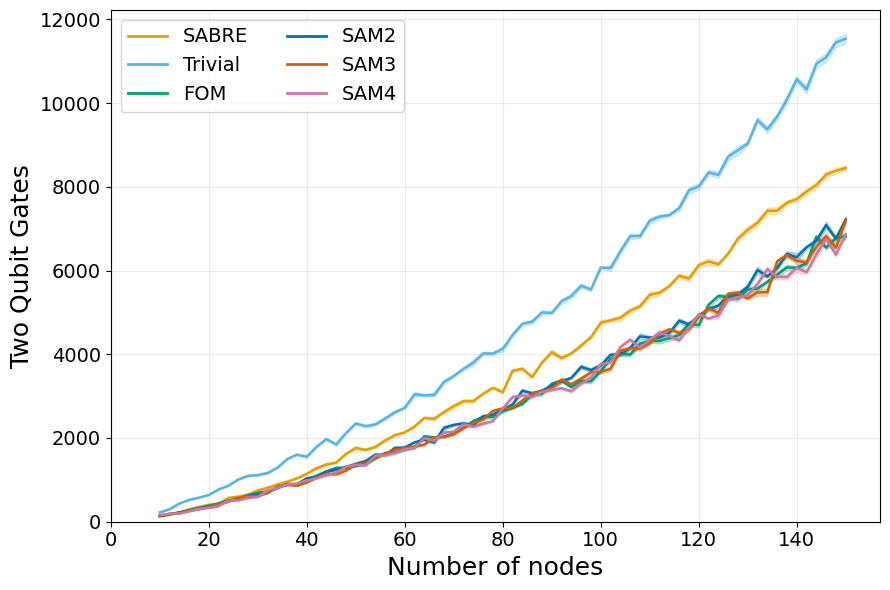

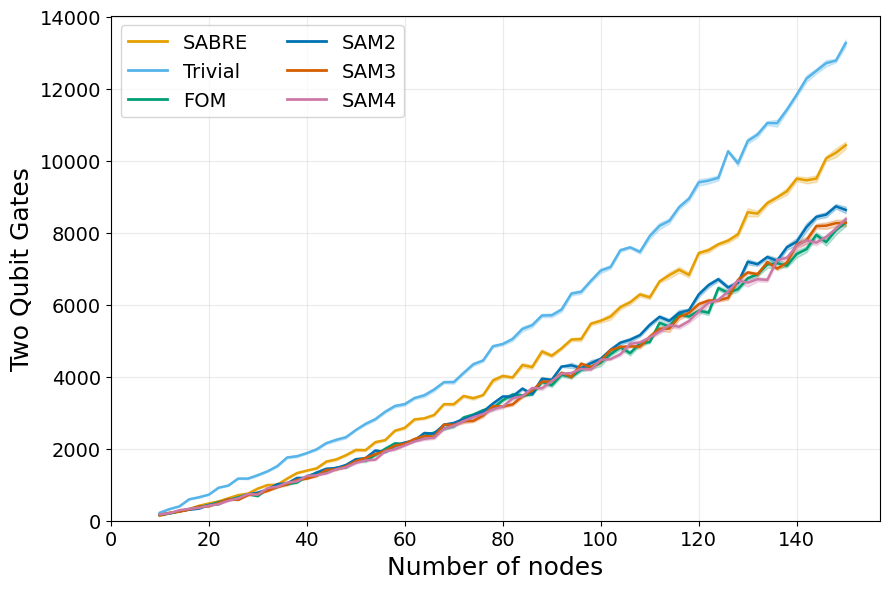

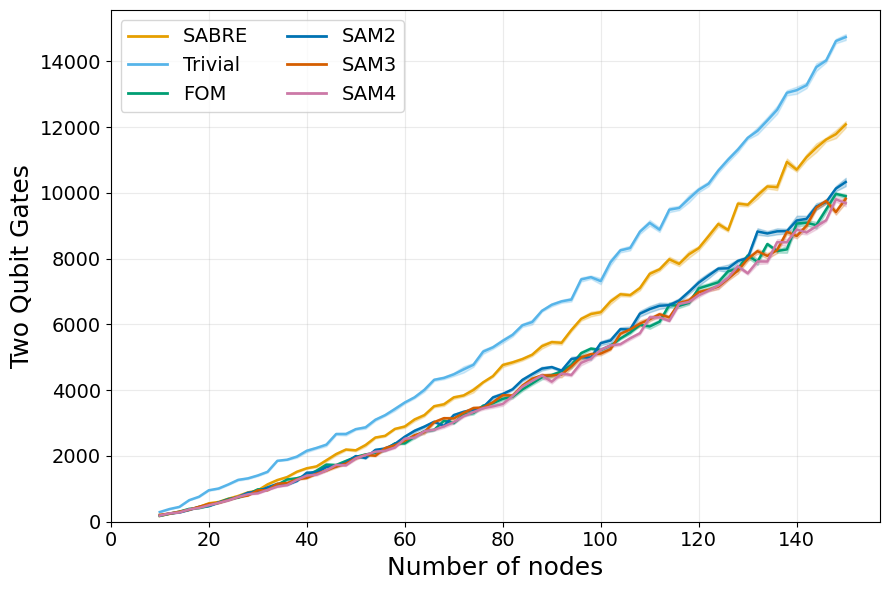

In [141]:
_plot_quality_by_parameter('reg', 'two_qubit_gates', [2], 'Mean two-qubit gates, opt level 2')


### 4. Number of nodes vs mean two-qubit gate count, optimization level 3


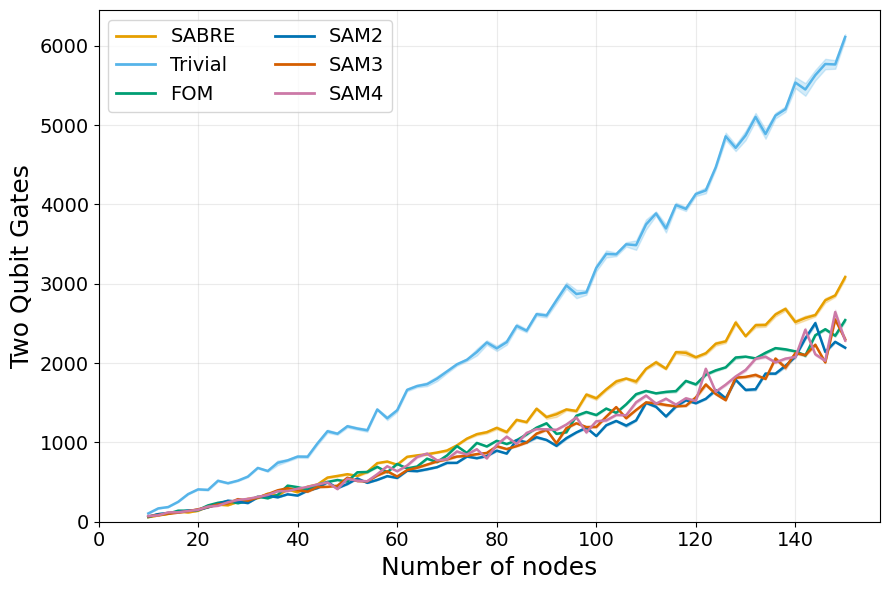

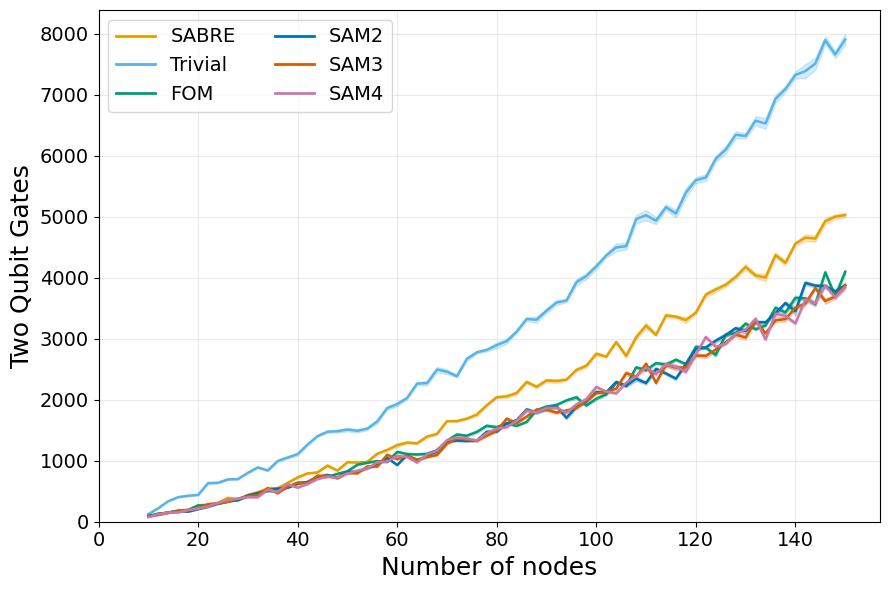

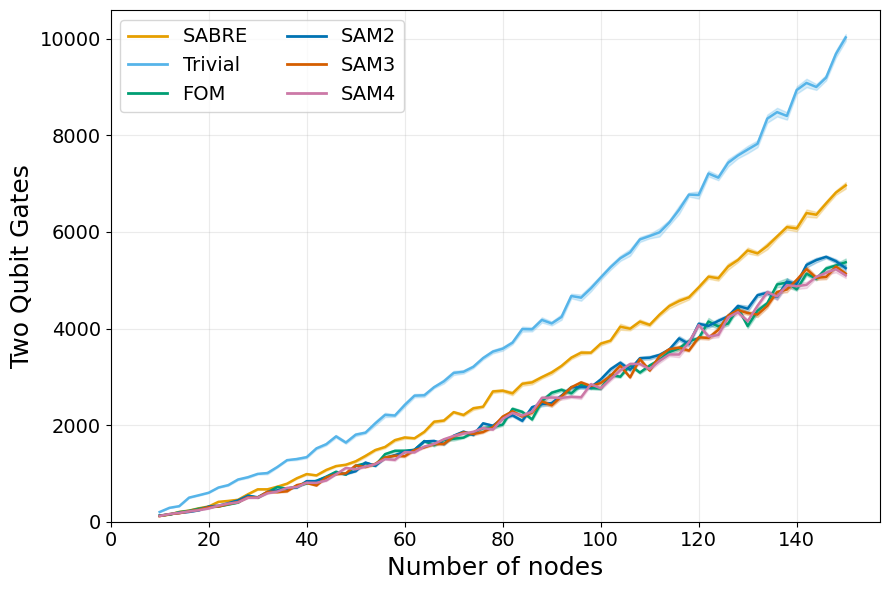

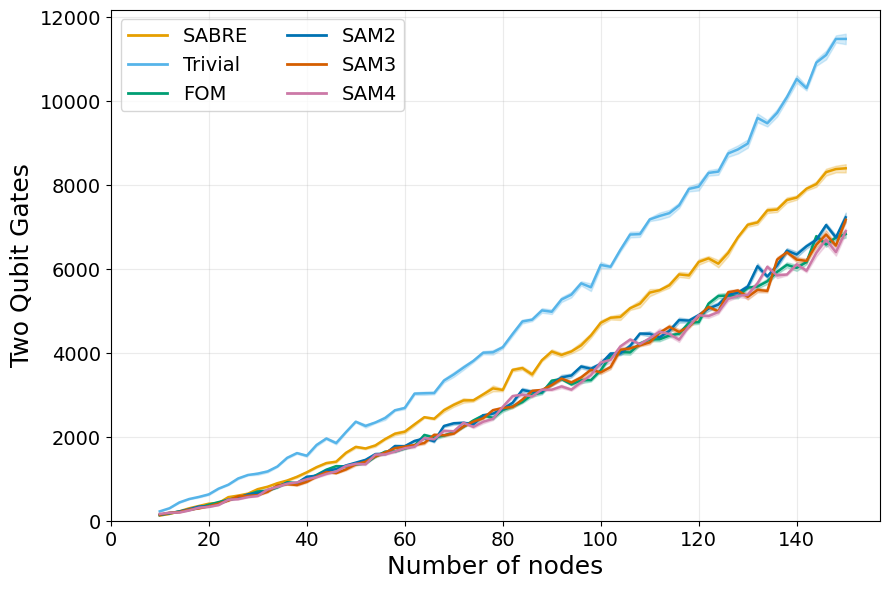

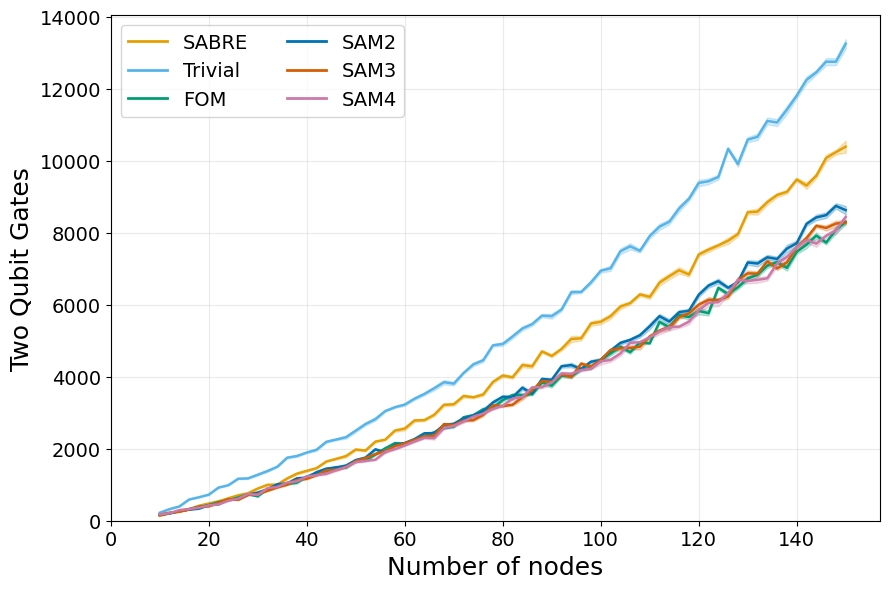

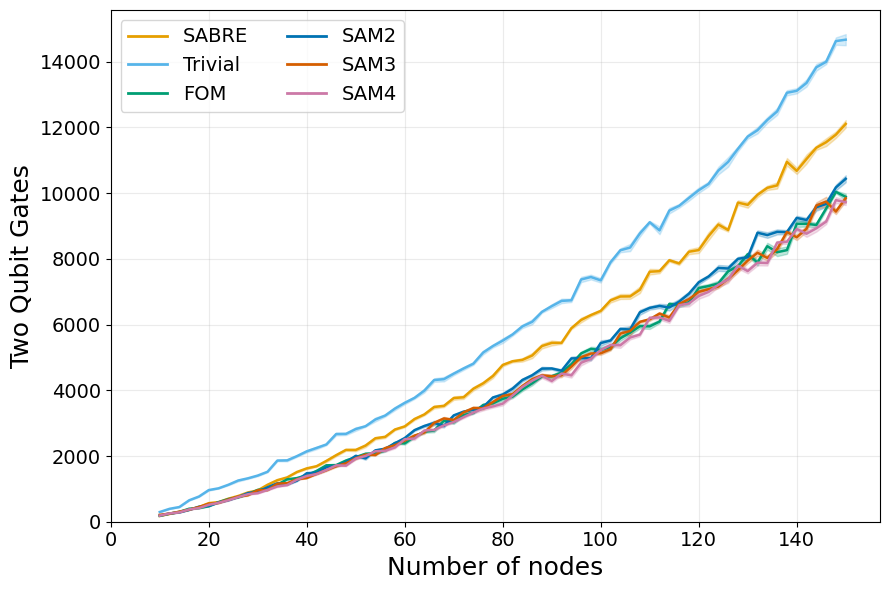

In [142]:
_plot_quality_by_parameter('reg', 'two_qubit_gates', [3], 'Mean two-qubit gates, opt level 3')


### 4. Number of nodes vs mean circuit depth, optimization level 1


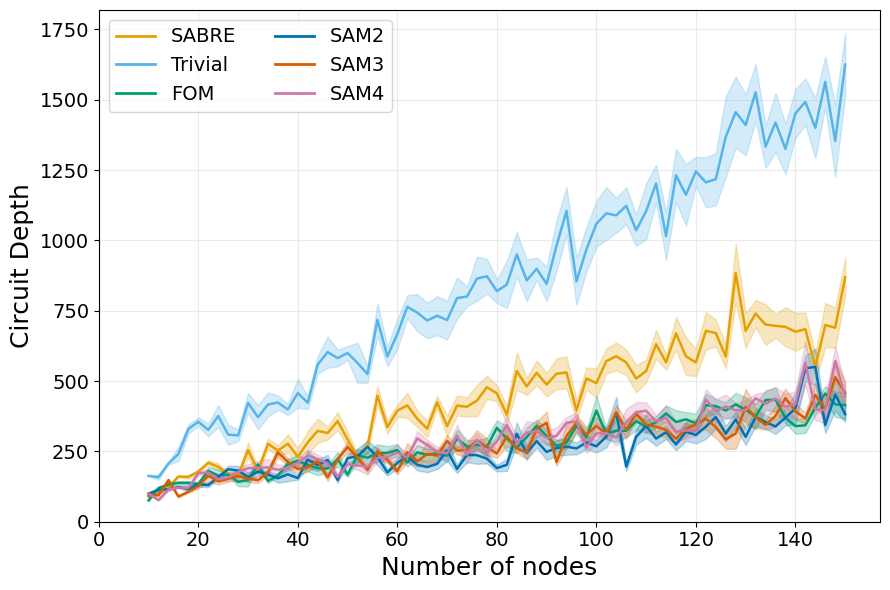

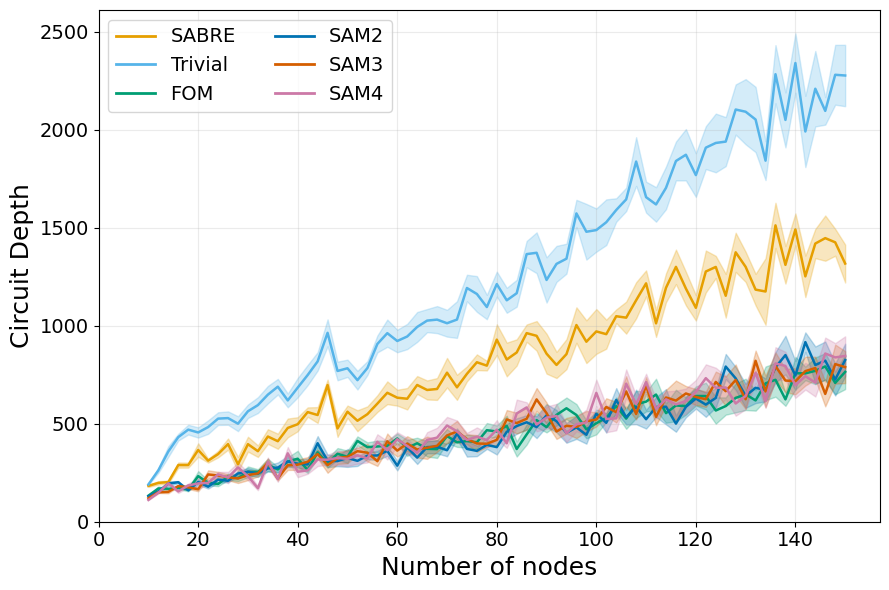

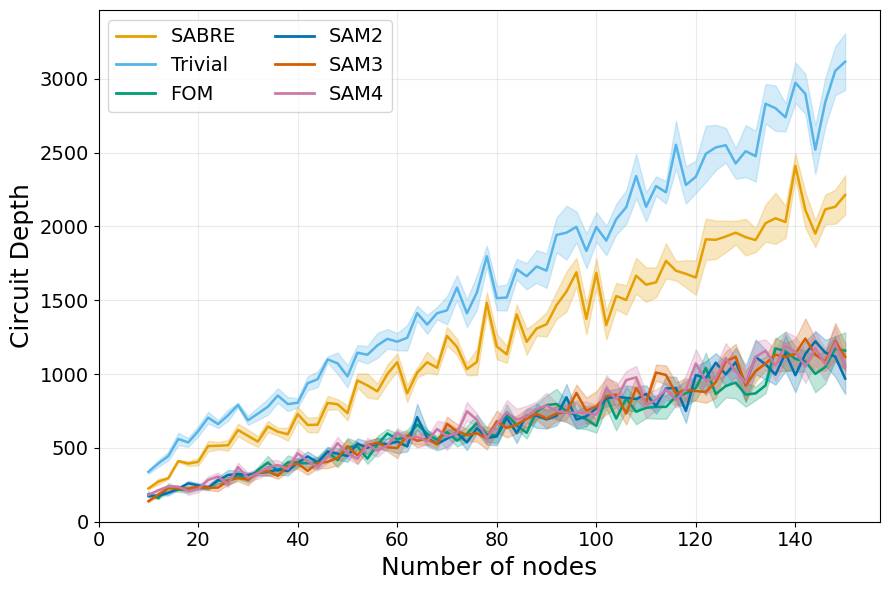

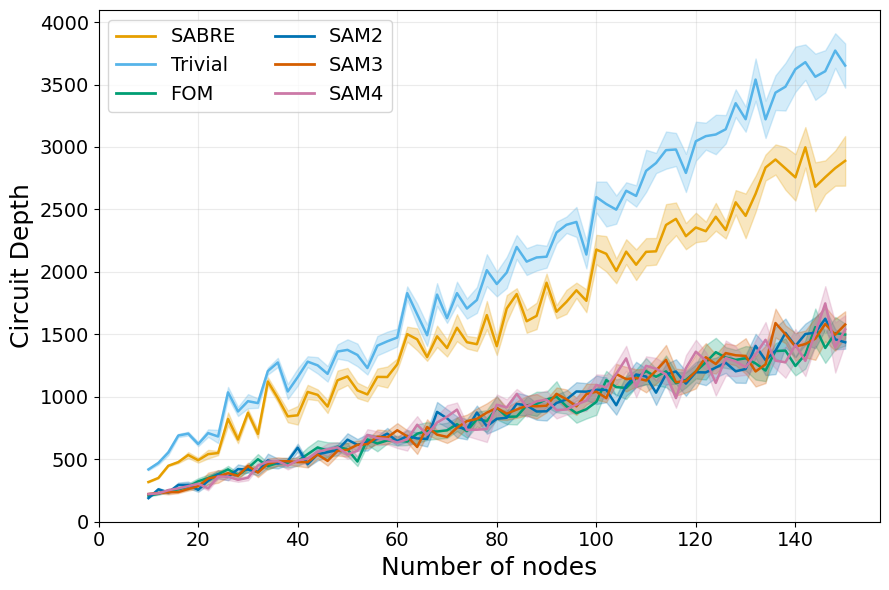

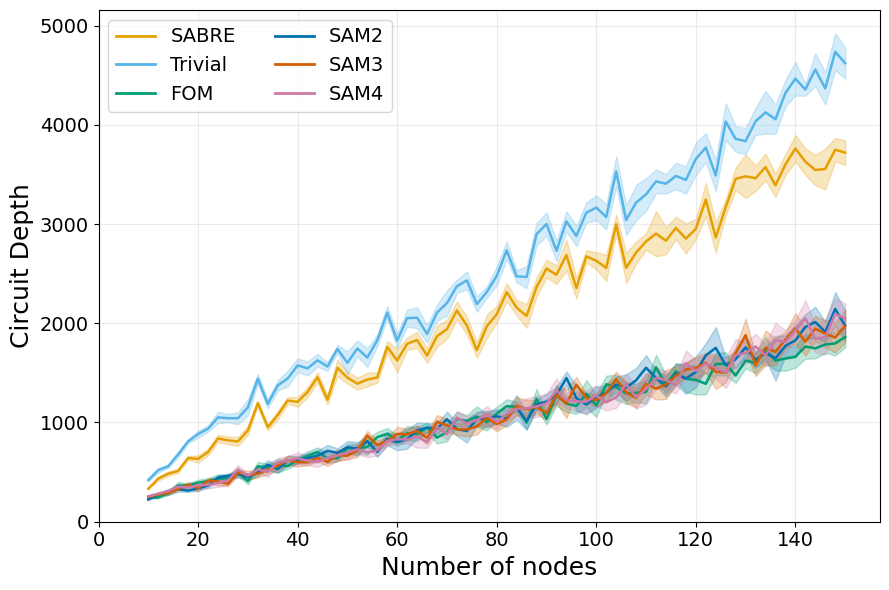

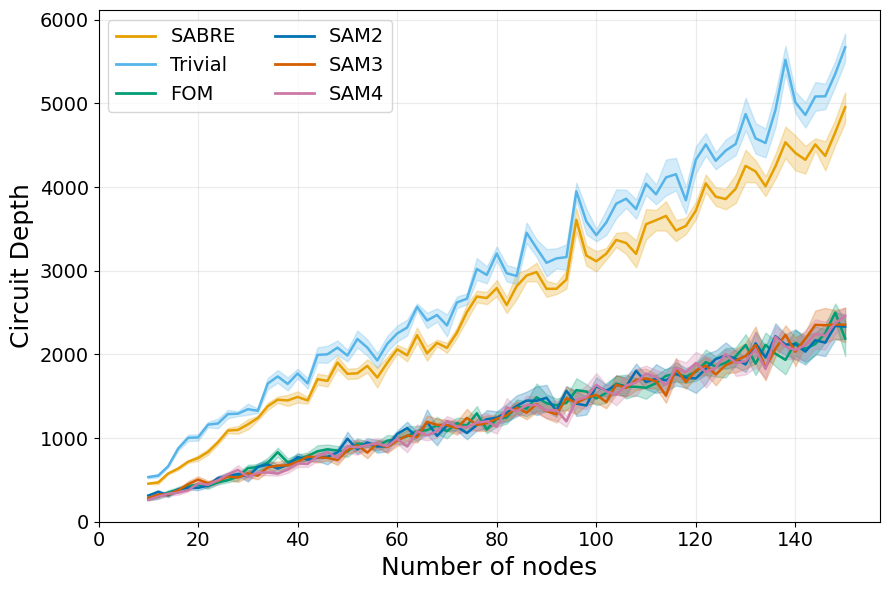

In [143]:
_plot_quality_by_parameter('reg', 'circuit_depth', [1], 'Mean circuit depth, opt level 1')


### 6. Number of nodes vs mean circuit depth, optimization level 2


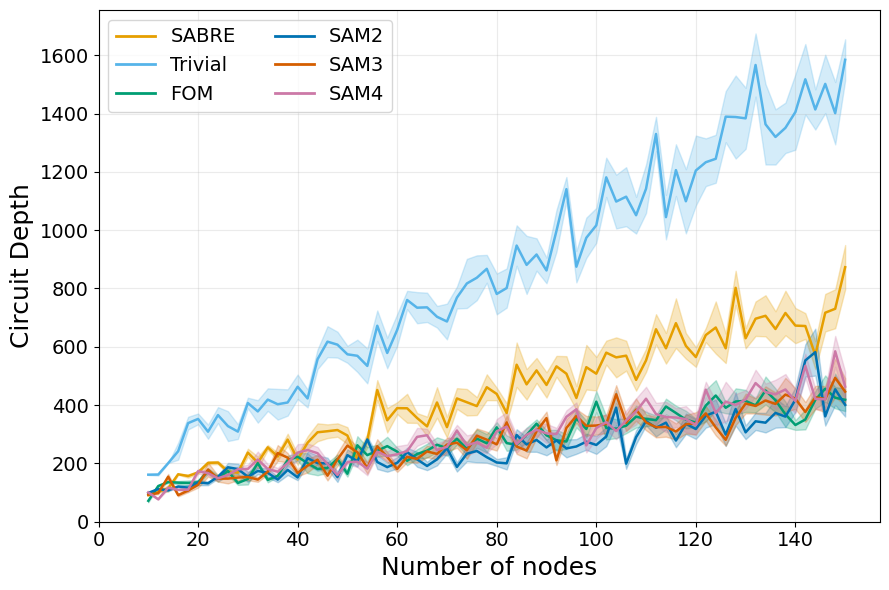

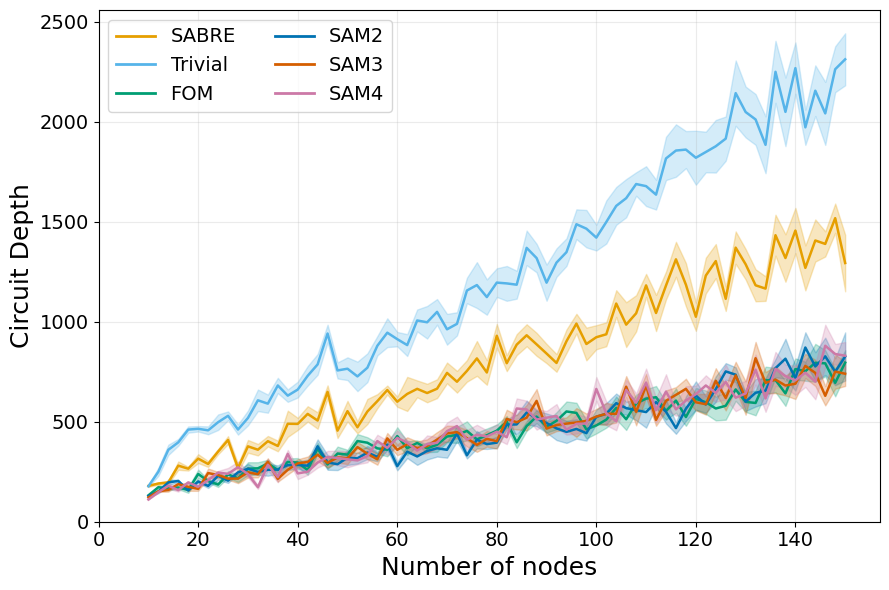

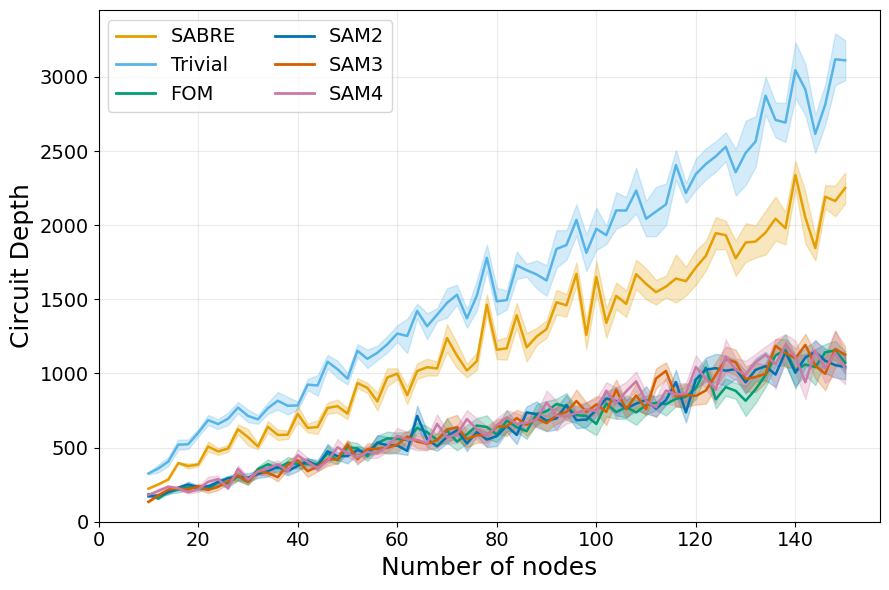

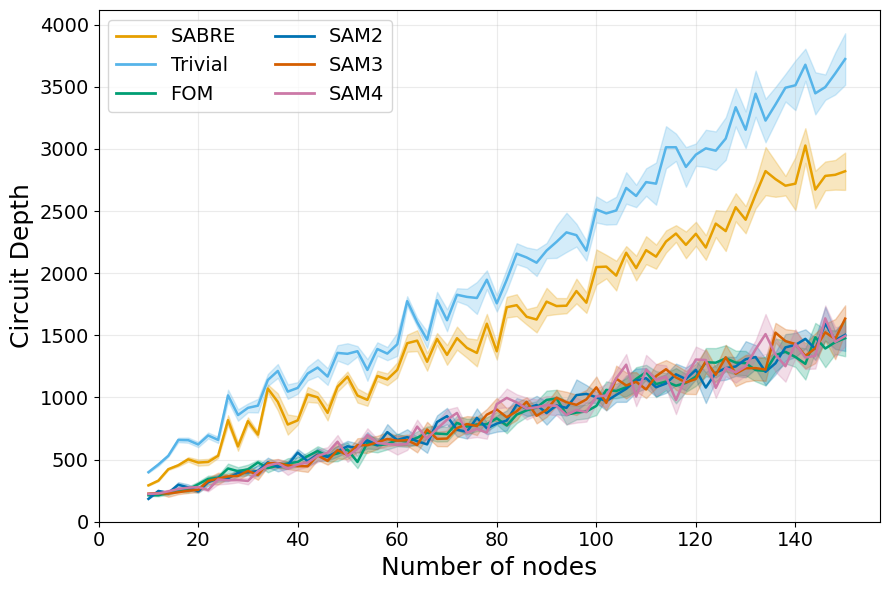

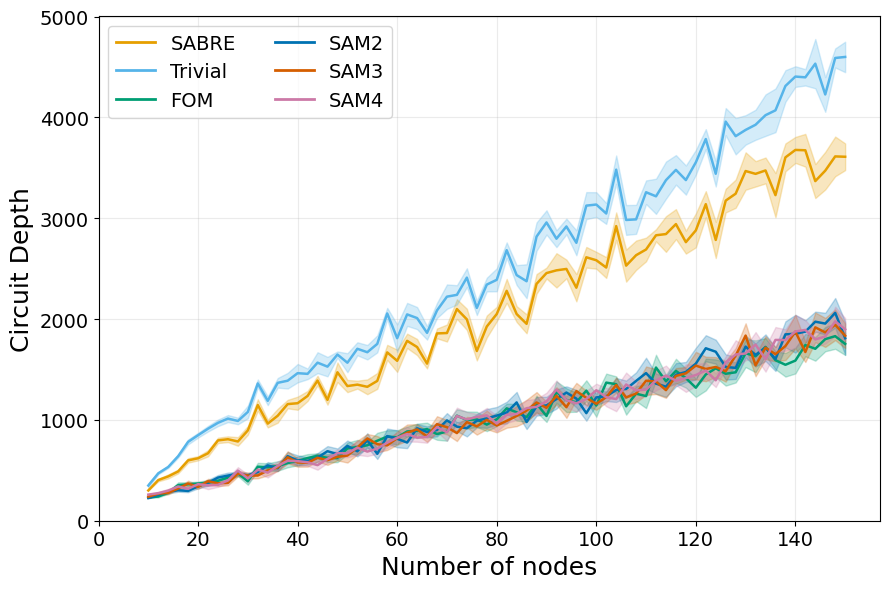

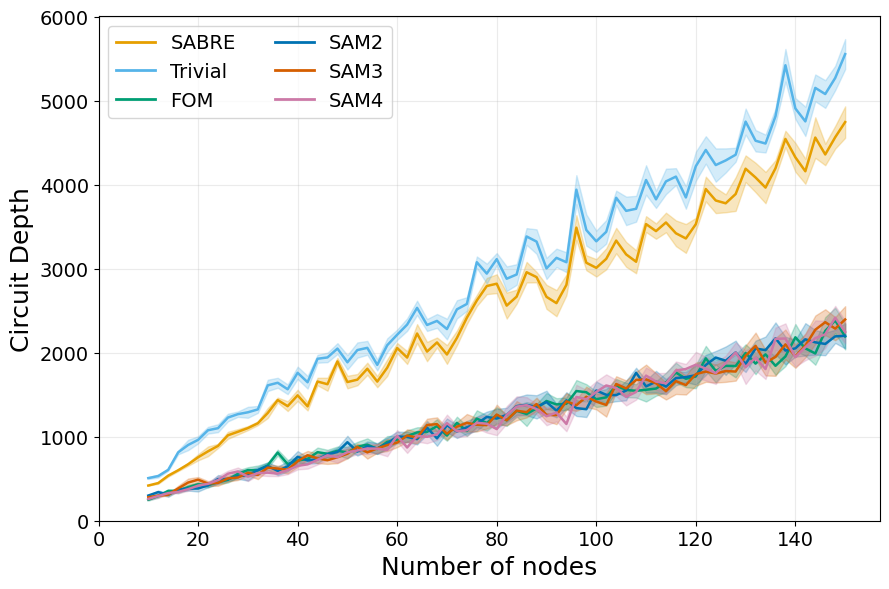

In [144]:
_plot_quality_by_parameter('reg', 'circuit_depth', [2], 'Mean circuit depth, opt level 2')


### 7. Number of nodes vs mean circuit depth, optimization level 3


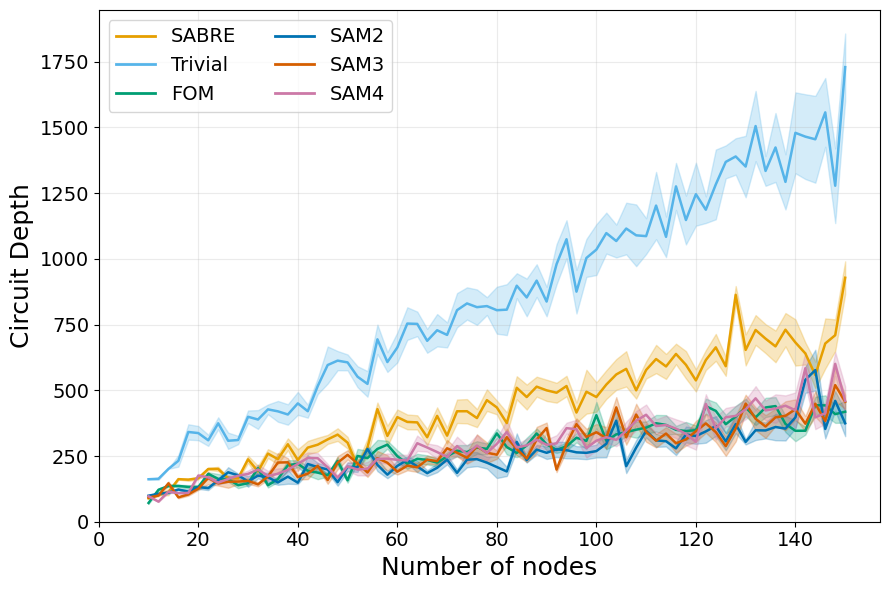

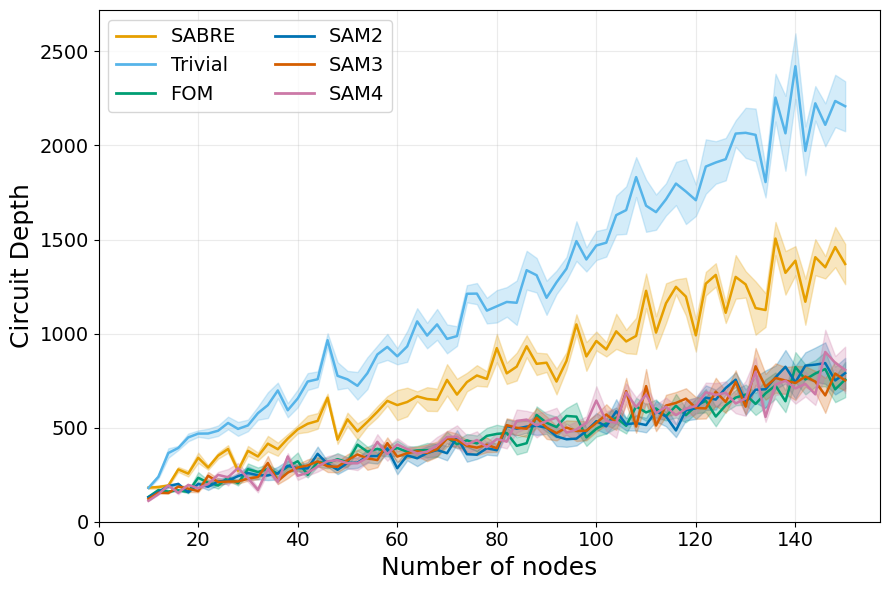

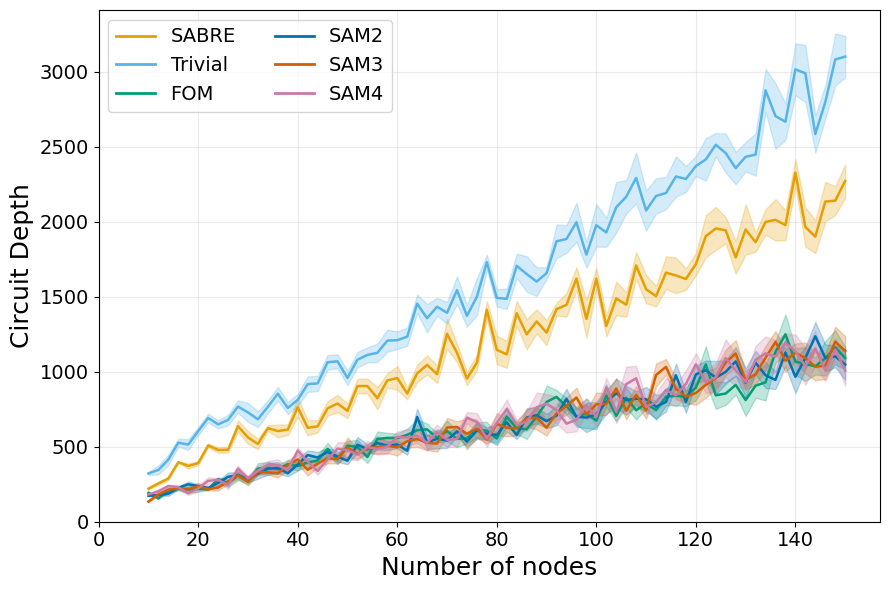

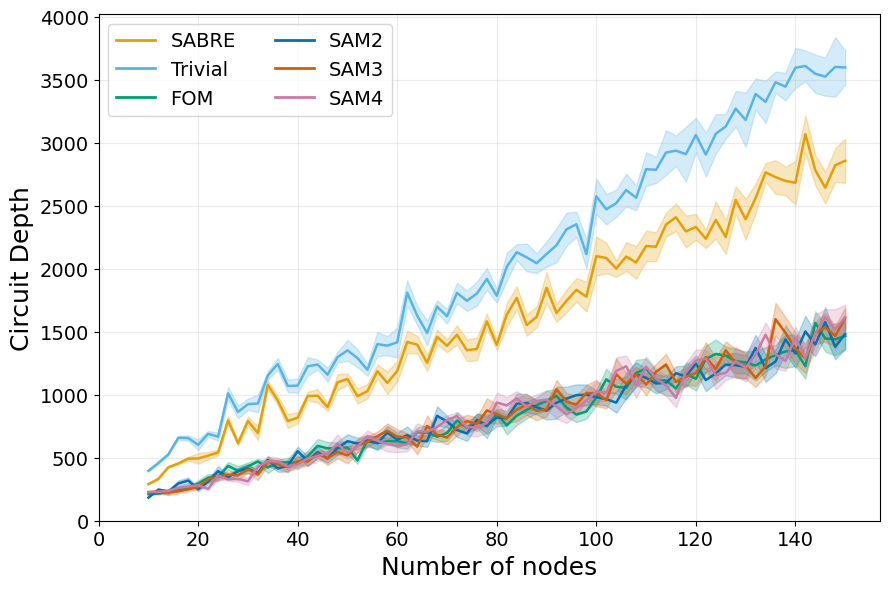

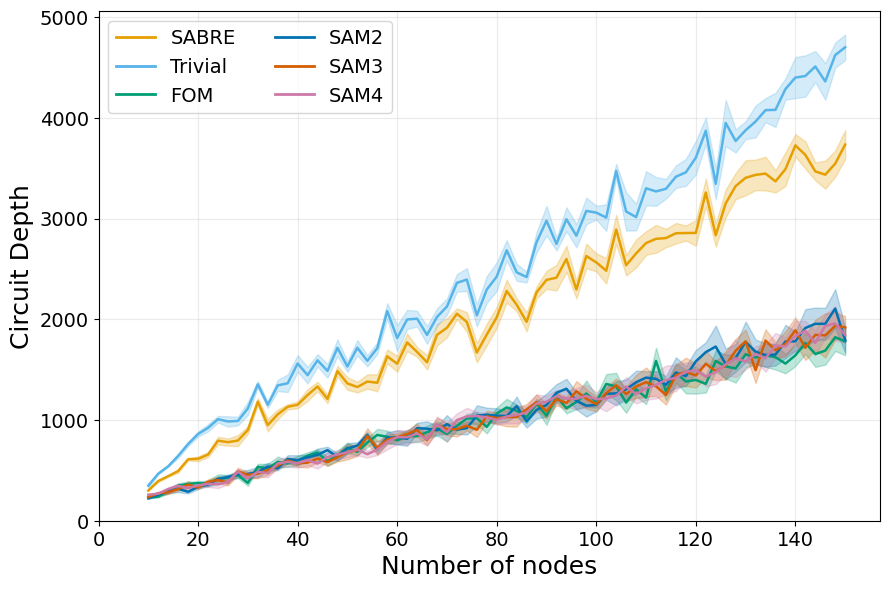

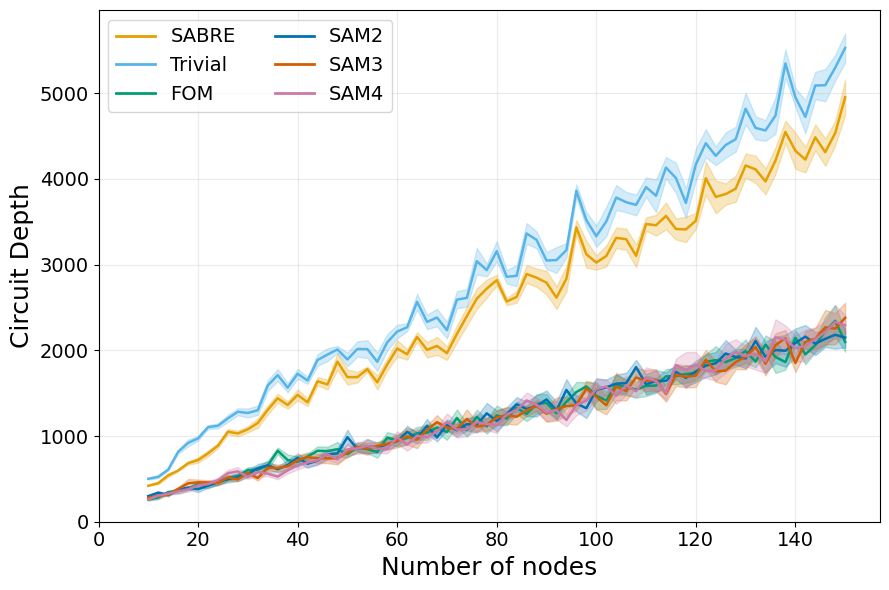

In [145]:
_plot_quality_by_parameter('reg', 'circuit_depth', [3], 'Mean circuit depth, opt level 3')


### 8. Number of nodes vs median mapping and total compilation time, optimization level 1


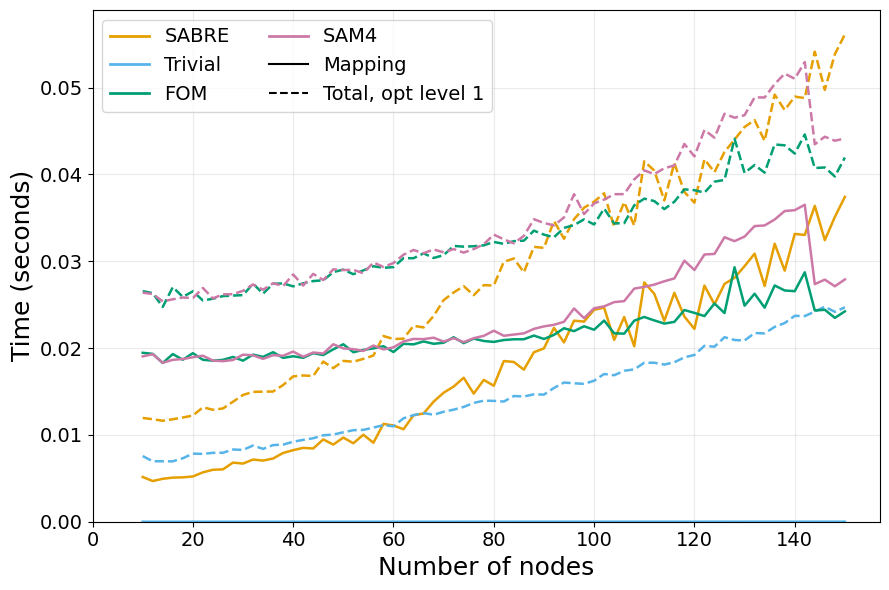

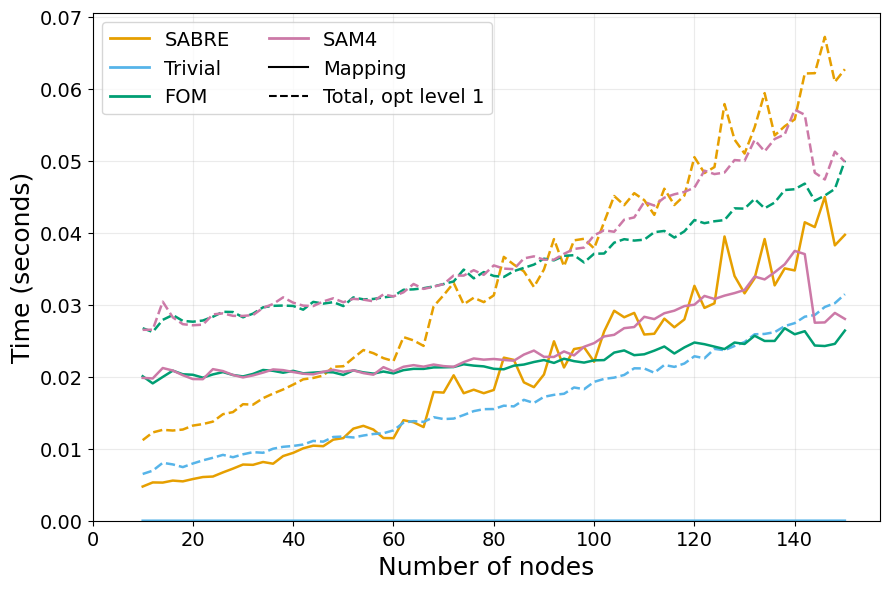

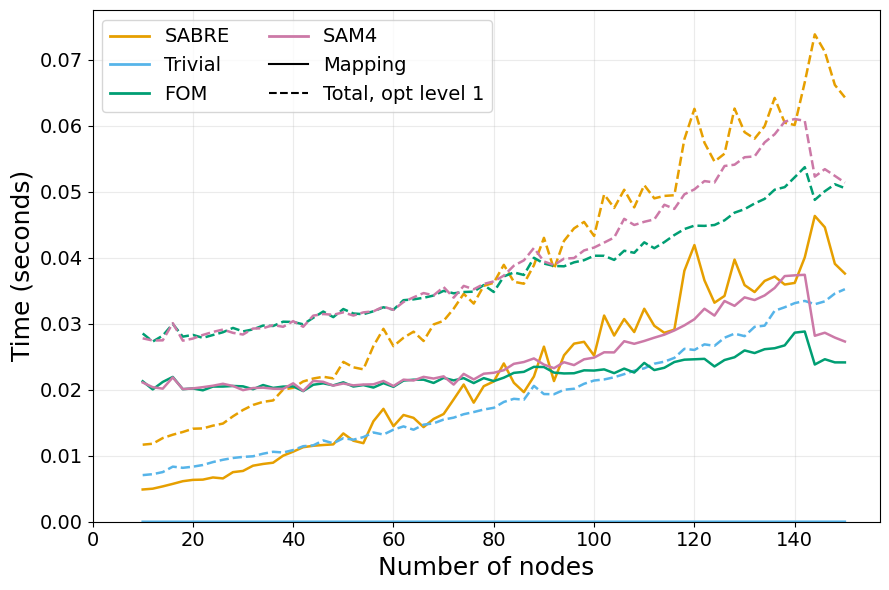

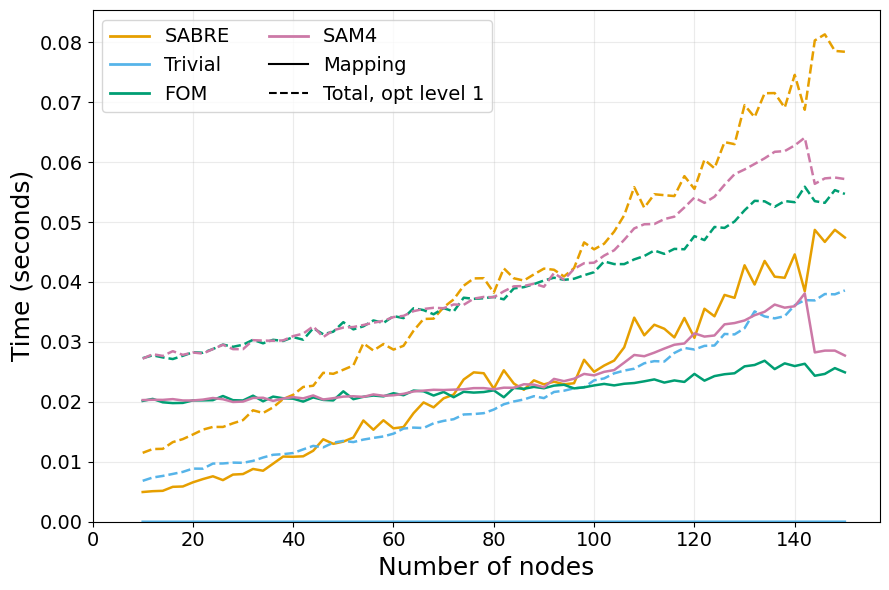

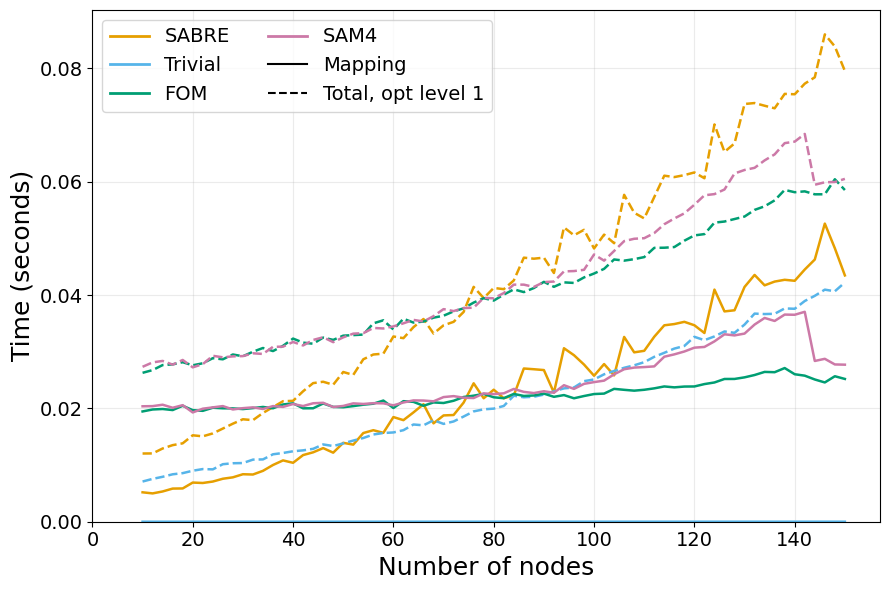

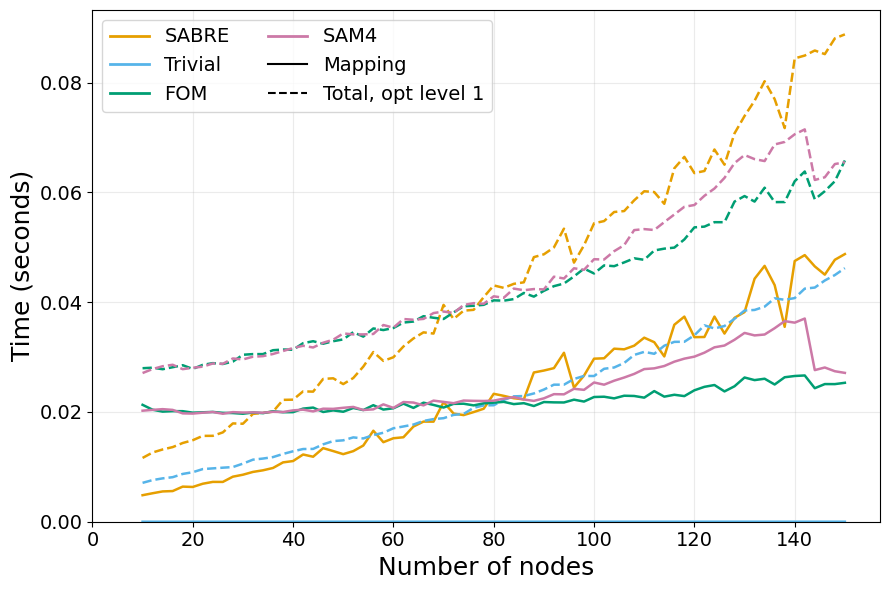

In [146]:
_plot_timing_by_parameter(
    'reg',
    'Median mapping and total compilation time, opt level 1',
    [
        ('mapping_time', None, '-', 'Mapping'),
        ('total_compilation_time', 1, '--', 'Total, opt level 1'),
    ],
    metric=1
)


### 9. Number of nodes vs median total compilation time, optimization levels 2 and 3


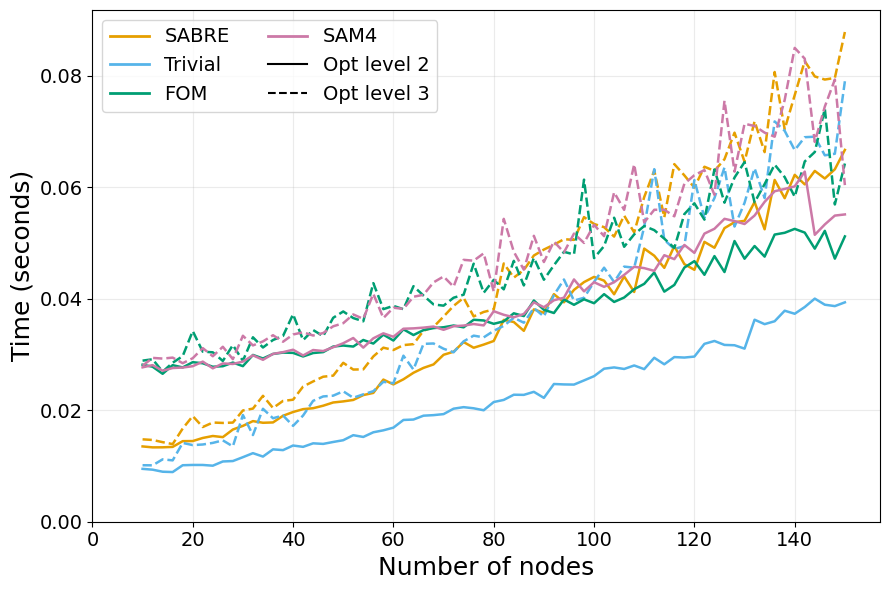

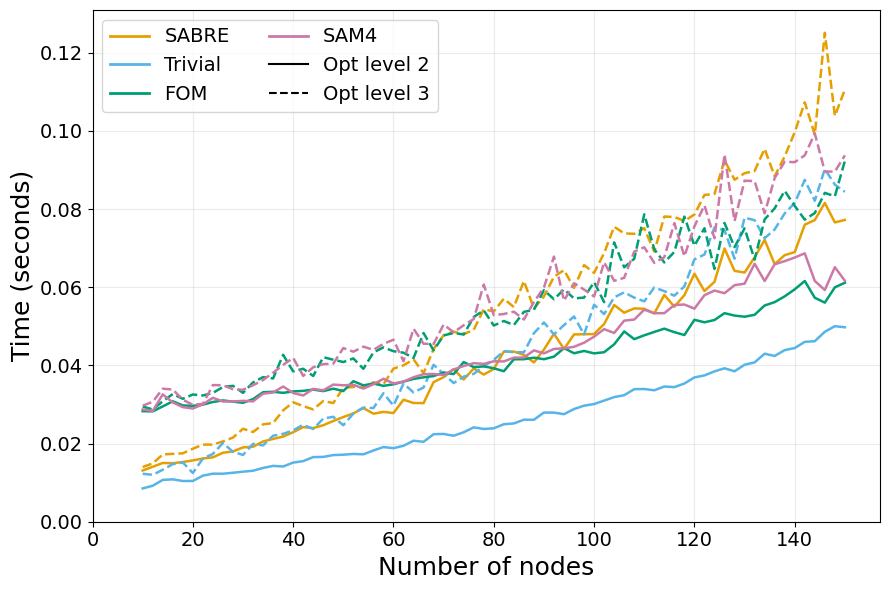

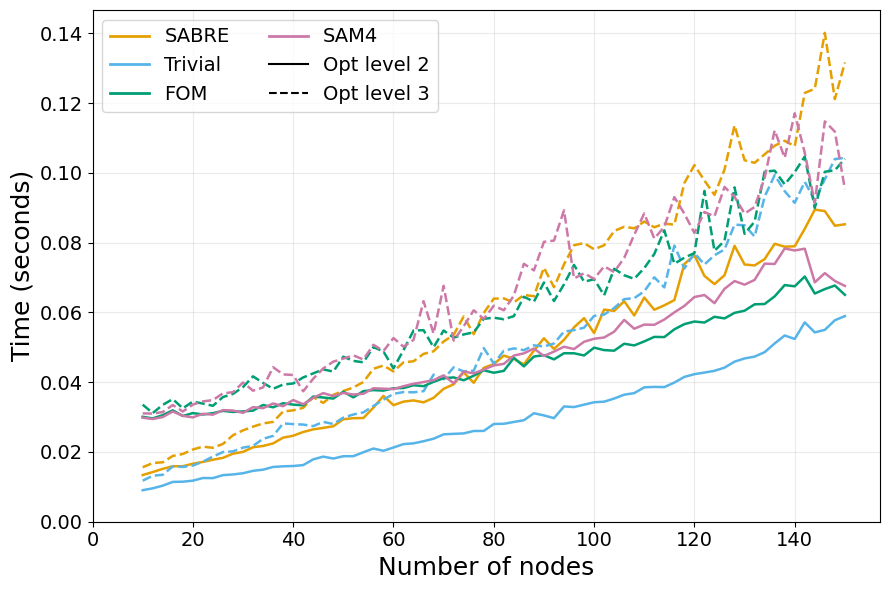

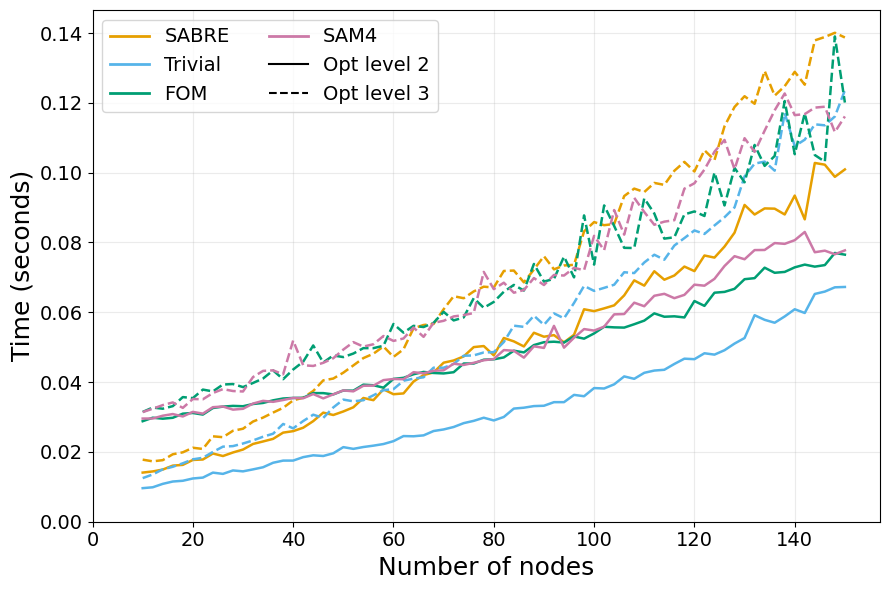

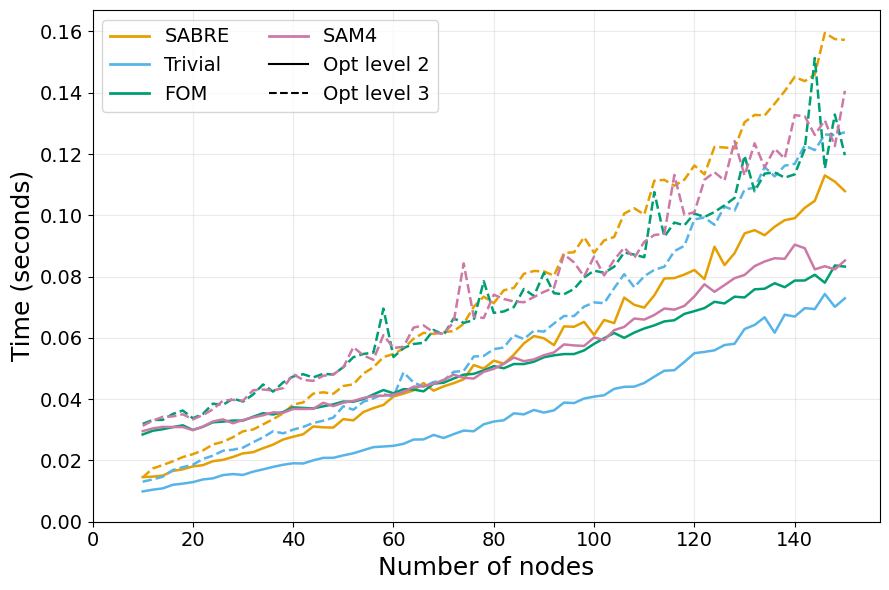

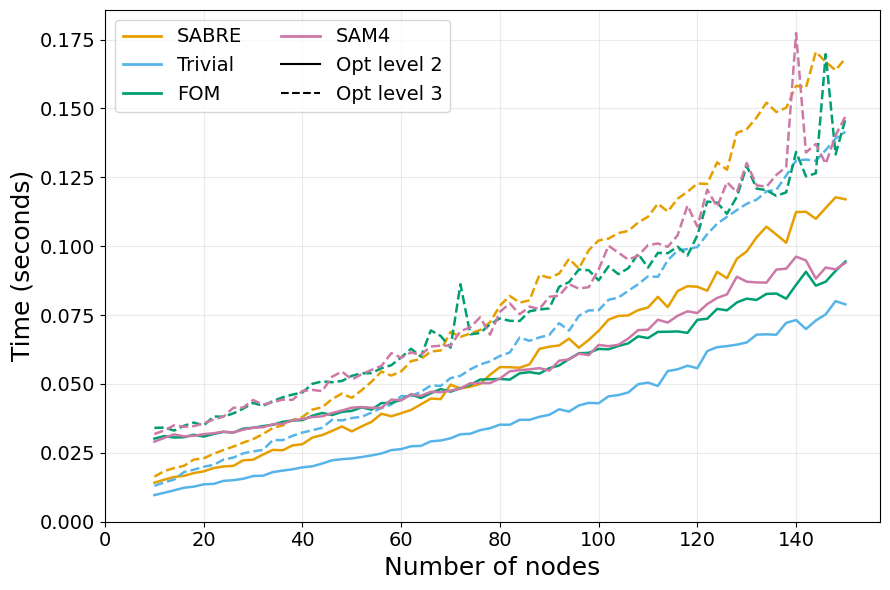

In [147]:
_plot_timing_by_parameter(
    'reg',
    'Median total compilation time, opt levels 2 and 3',
    [
        ('total_compilation_time', 2, '-', 'Opt level 2'),
        ('total_compilation_time', 3, '--', 'Opt level 3'),
    ],
    metric=2
)


## Barabasi-Albert graphs


### 1. Number of nodes vs mean routed SWAP count


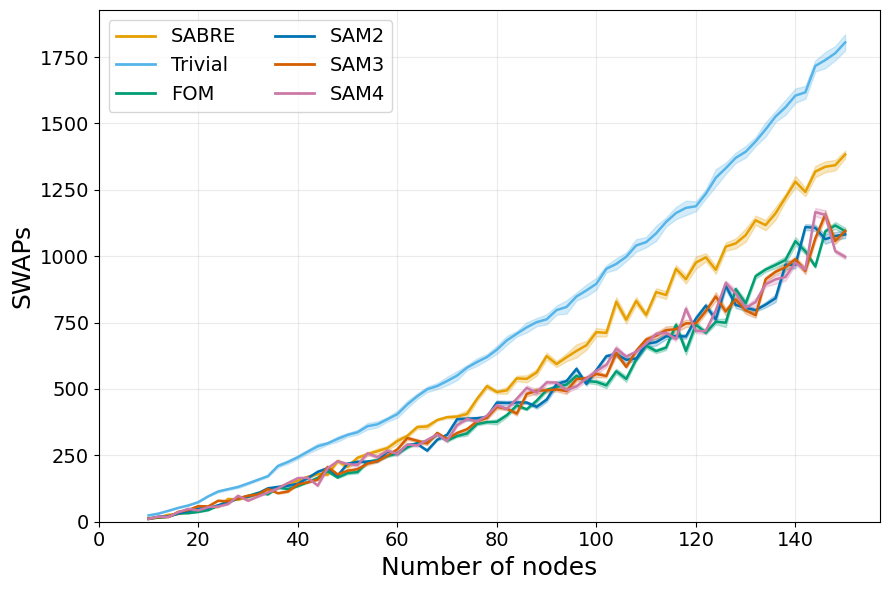

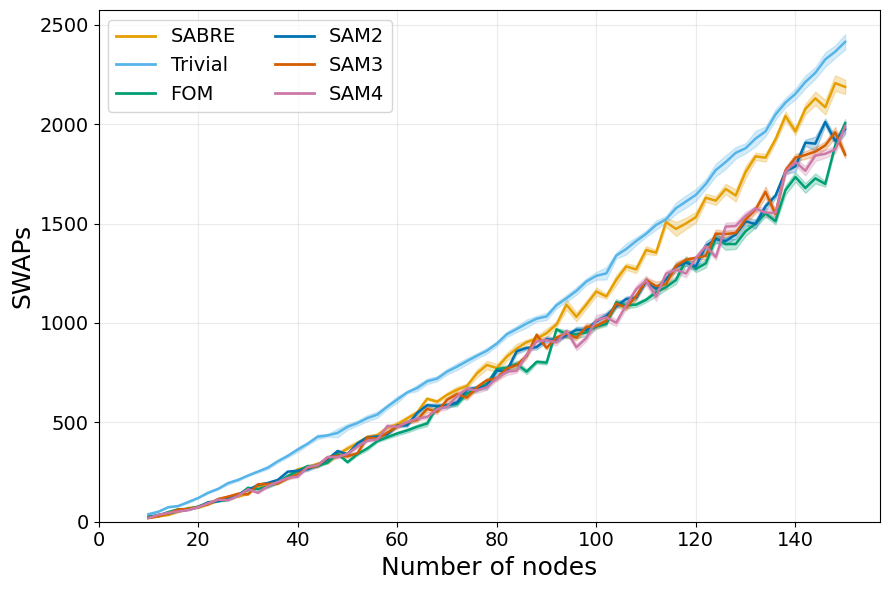

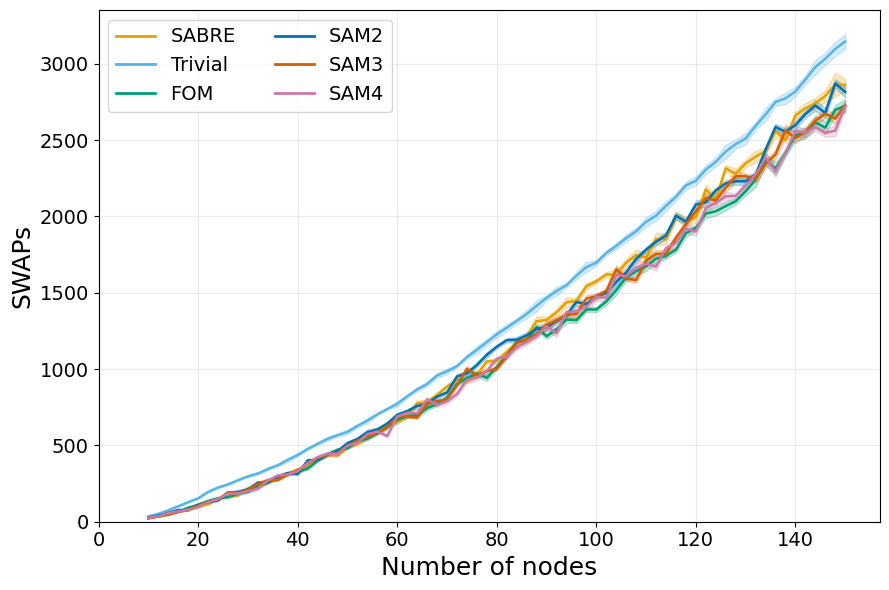

In [148]:
_plot_quality_by_parameter('ba', 'swaps', [], 'Mean routed SWAP count')


### 2. Number of nodes vs mean two-qubit gate count, optimization level 1


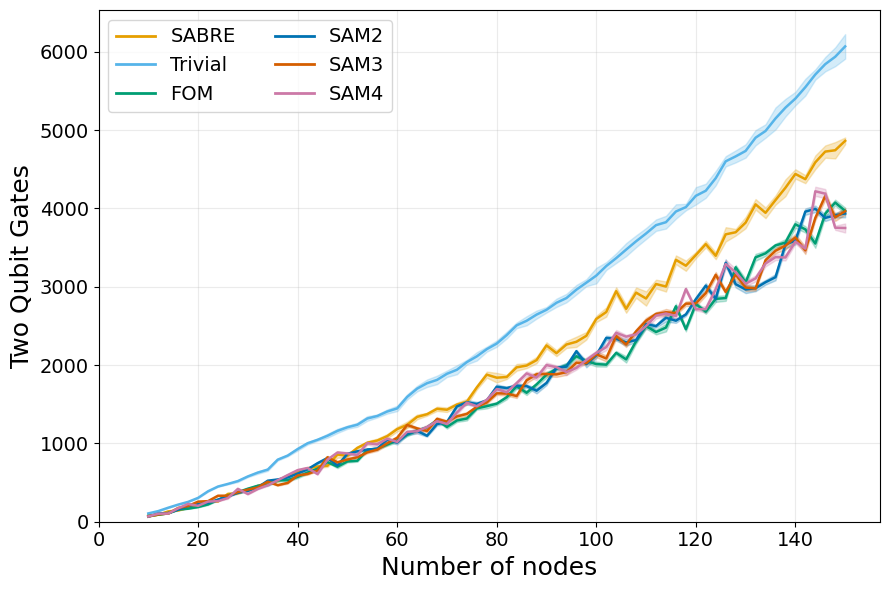

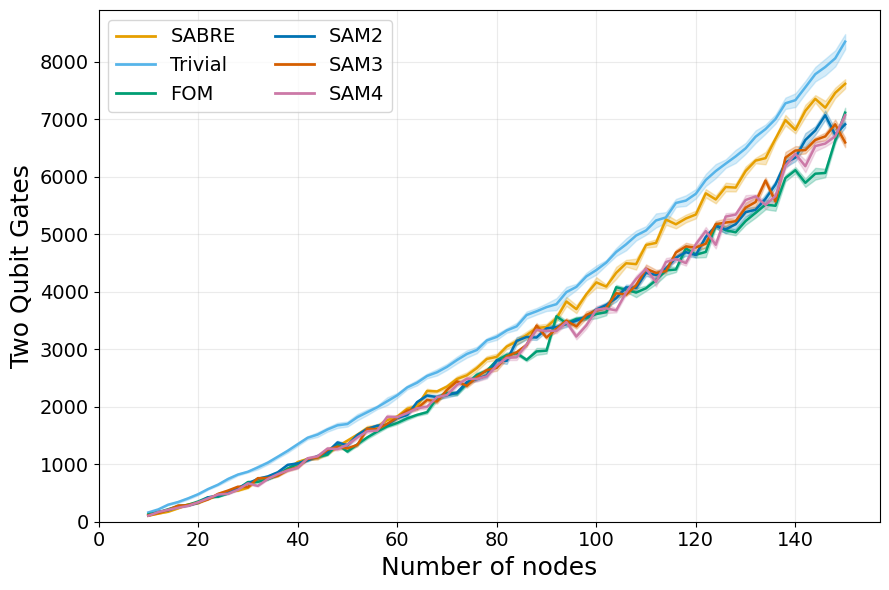

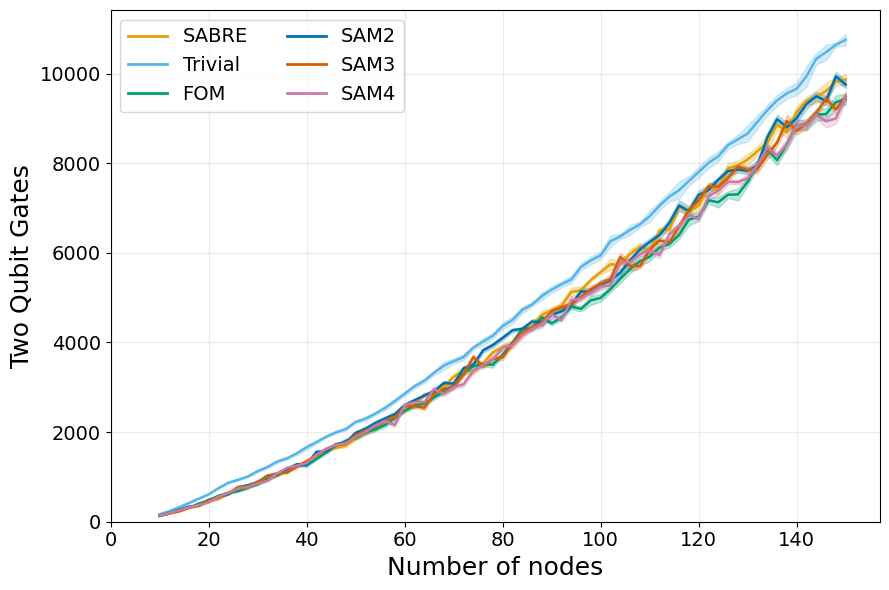

In [149]:
_plot_quality_by_parameter('ba', 'two_qubit_gates', [1], 'Mean two-qubit gates, opt level 1')


### 3. Number of nodes vs mean two-qubit gate count, optimization level 2


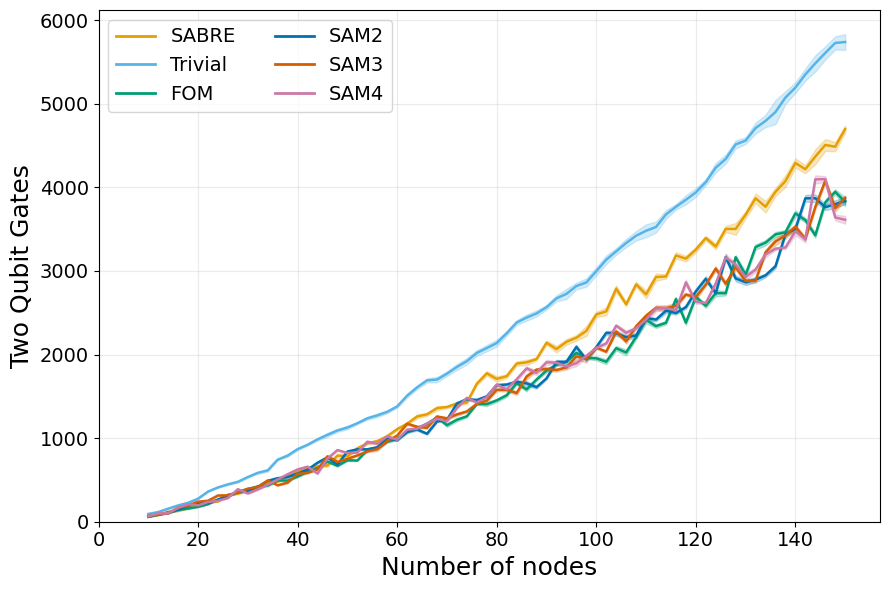

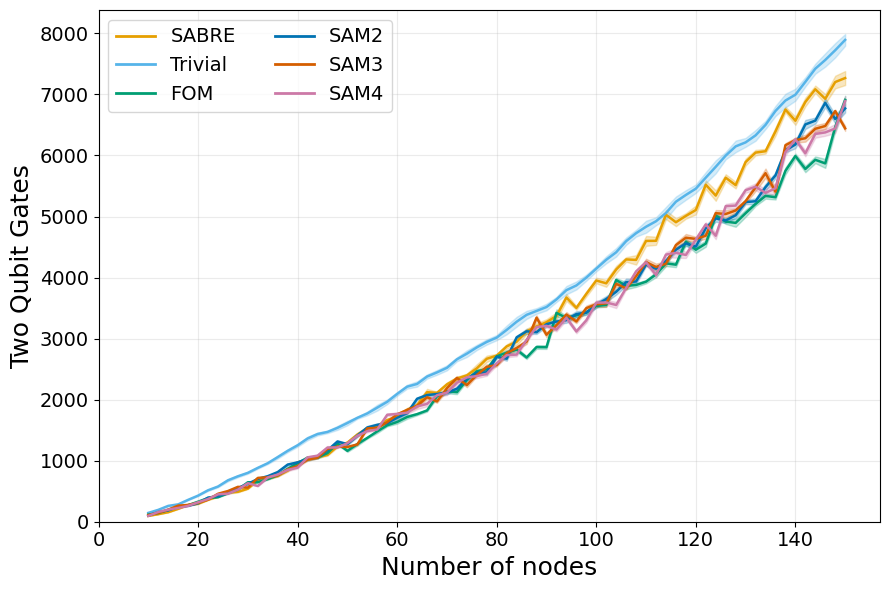

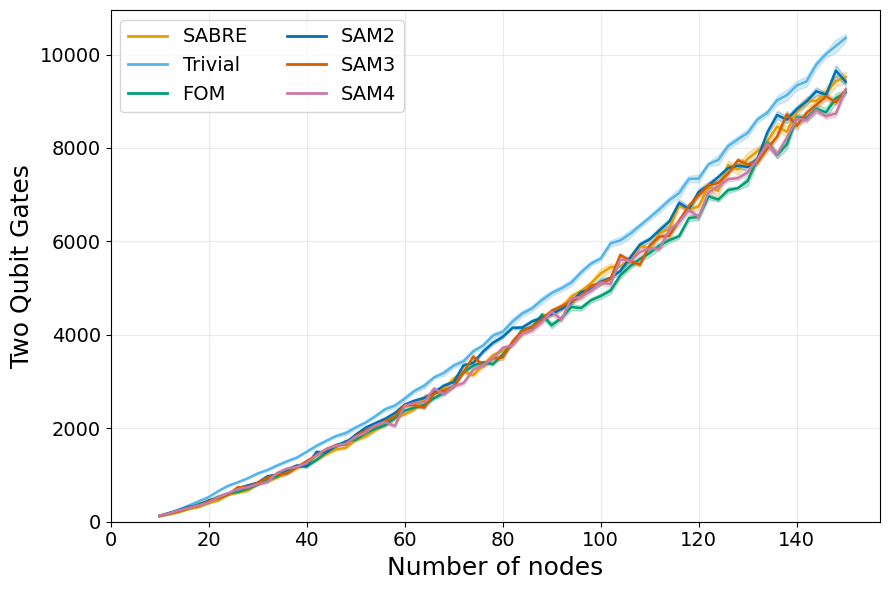

In [150]:
_plot_quality_by_parameter('ba', 'two_qubit_gates', [2], 'Mean two-qubit gates, opt level 2')


### 4. Number of nodes vs mean two-qubit gate count, optimization level 3


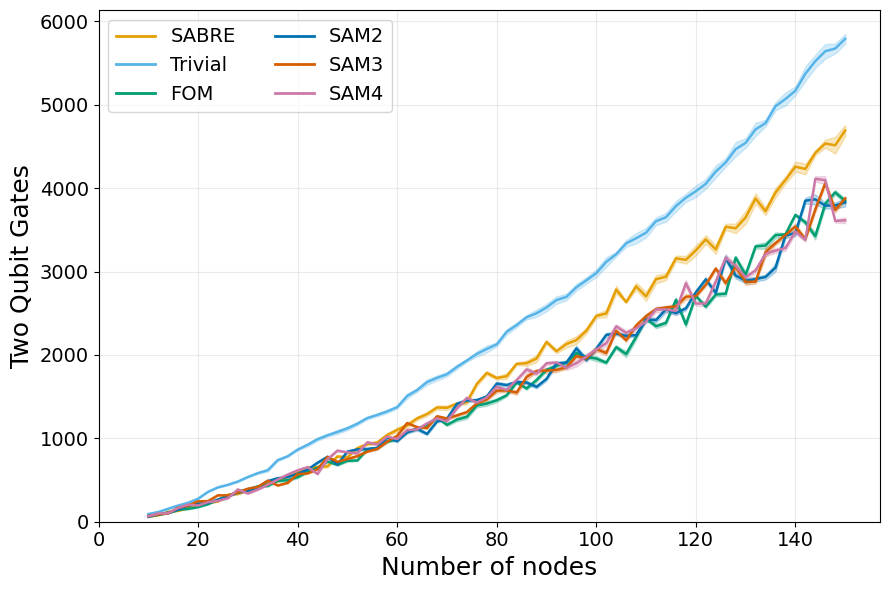

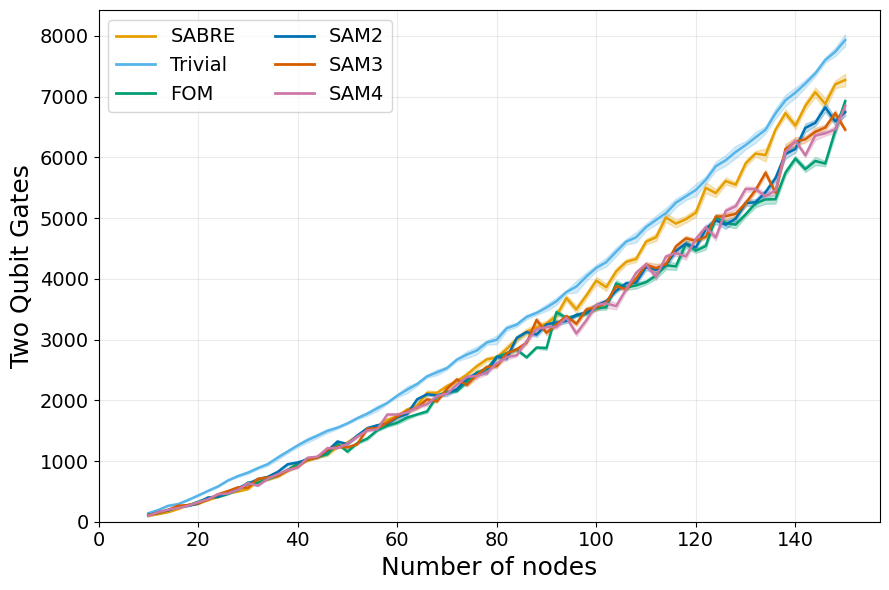

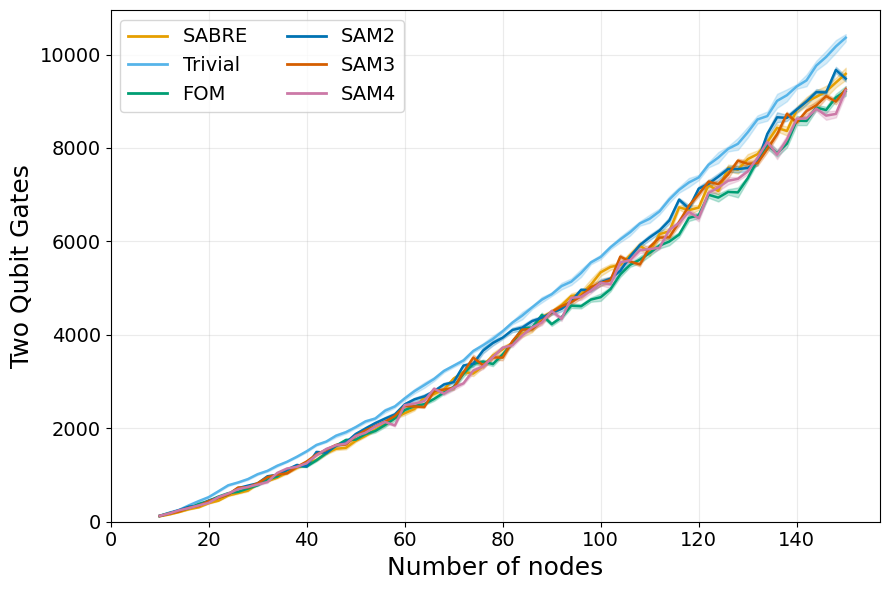

In [151]:
_plot_quality_by_parameter('ba', 'two_qubit_gates', [3], 'Mean two-qubit gates, opt level 3')


### 4. Number of nodes vs mean circuit depth, optimization level 1


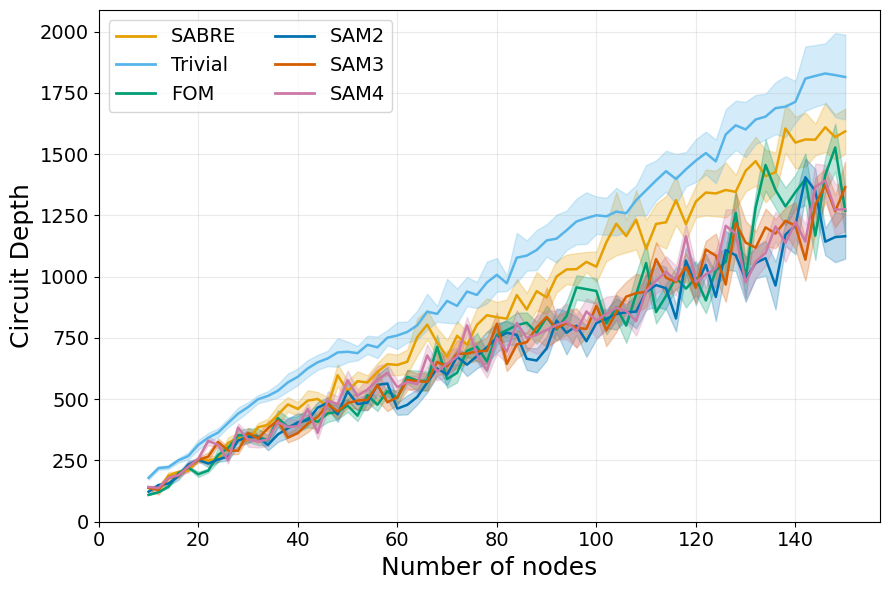

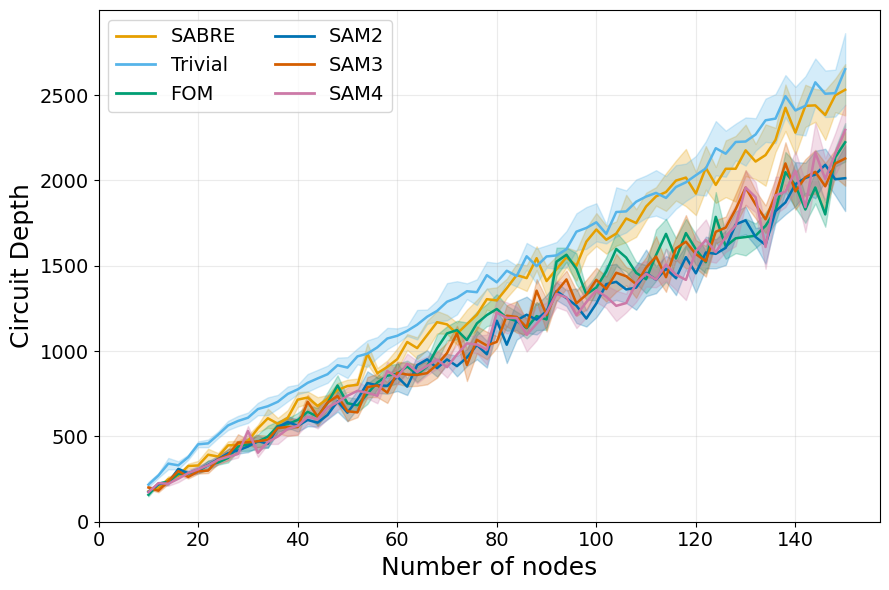

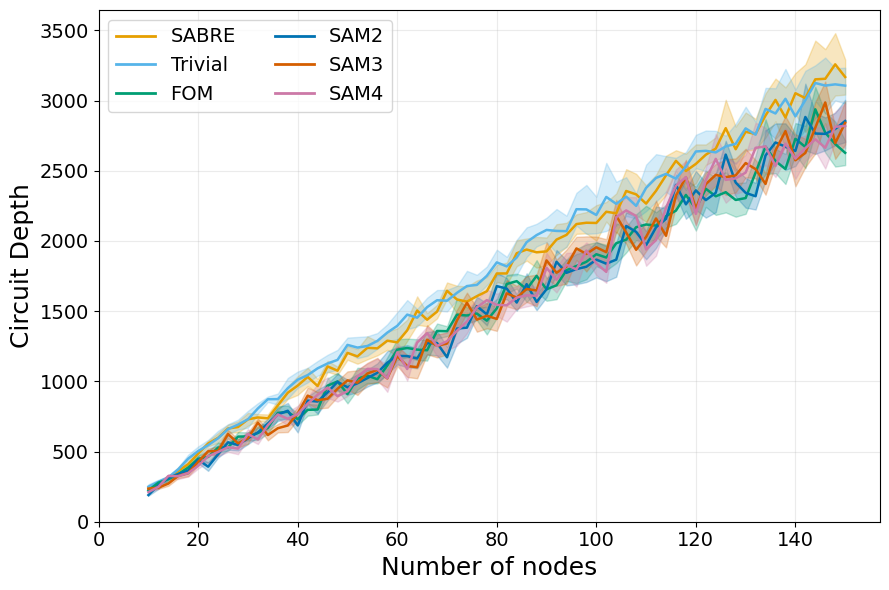

In [152]:
_plot_quality_by_parameter('ba', 'circuit_depth', [1], 'Mean circuit depth, opt level 1')


### 6. Number of nodes vs mean circuit depth, optimization level 2


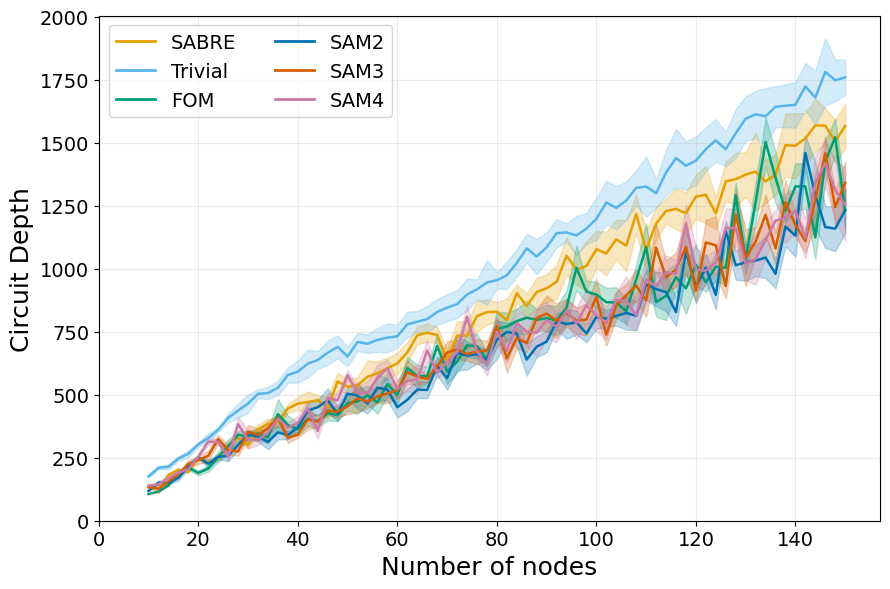

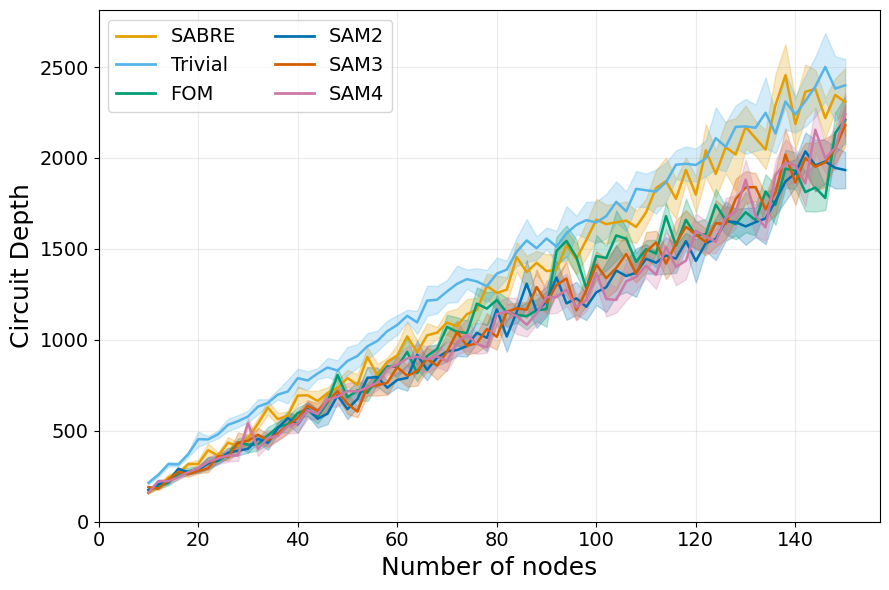

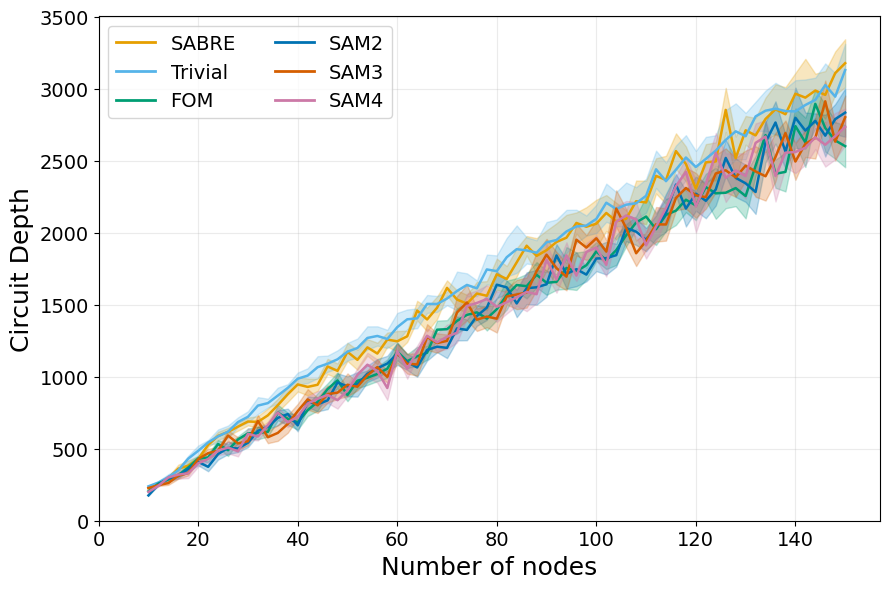

In [153]:
_plot_quality_by_parameter('ba', 'circuit_depth', [2], 'Mean circuit depth, opt level 2')


### 7. Number of nodes vs mean circuit depth, optimization level 3


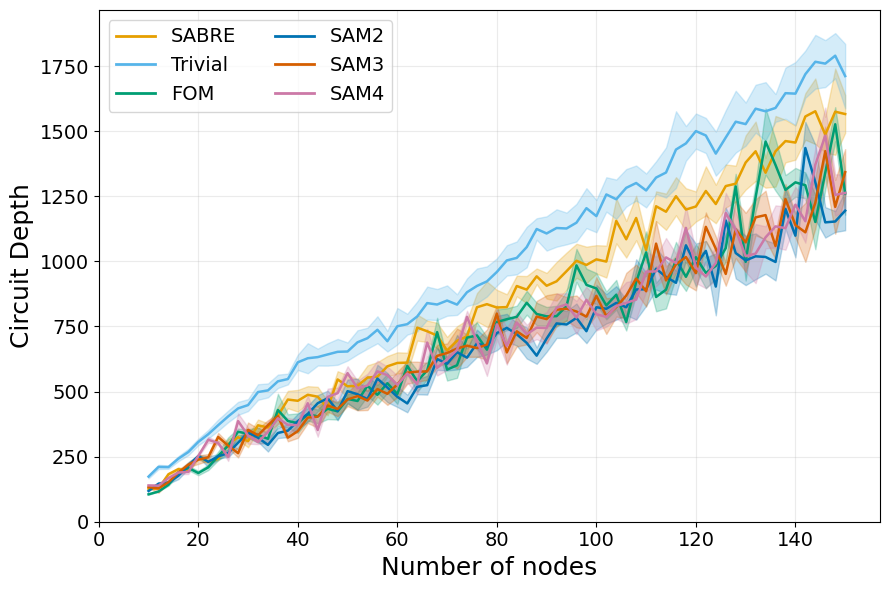

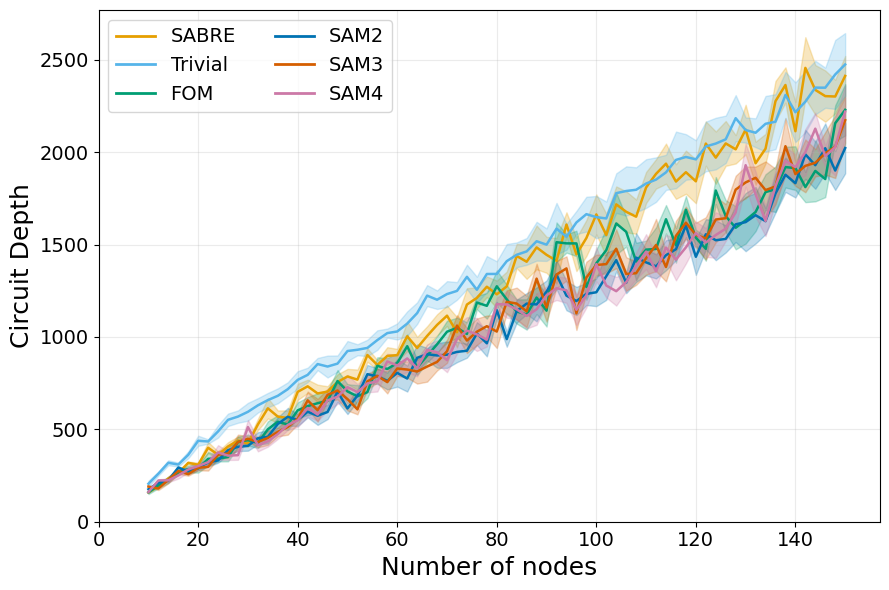

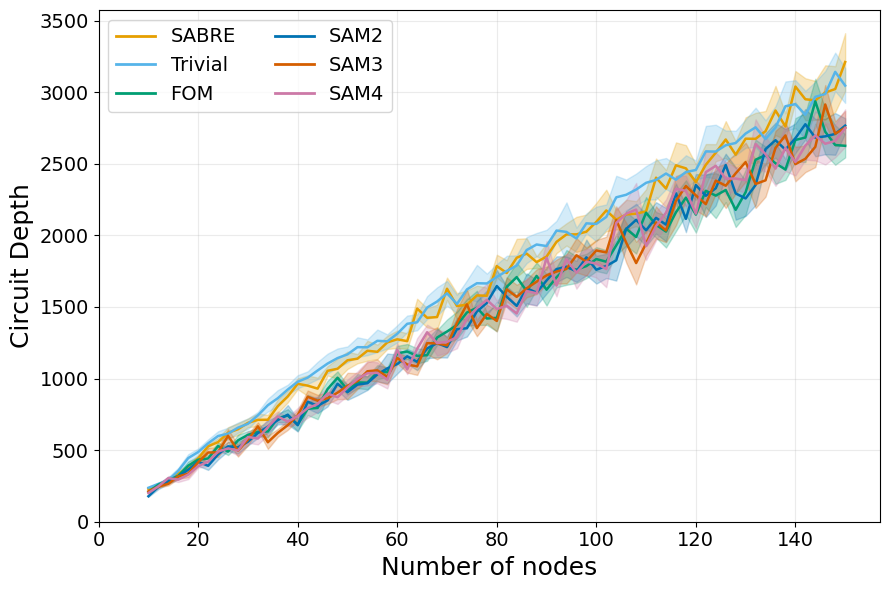

In [154]:
_plot_quality_by_parameter('ba', 'circuit_depth', [3], 'Mean circuit depth, opt level 3')


### 8. Number of nodes vs median mapping and total compilation time, optimization level 1


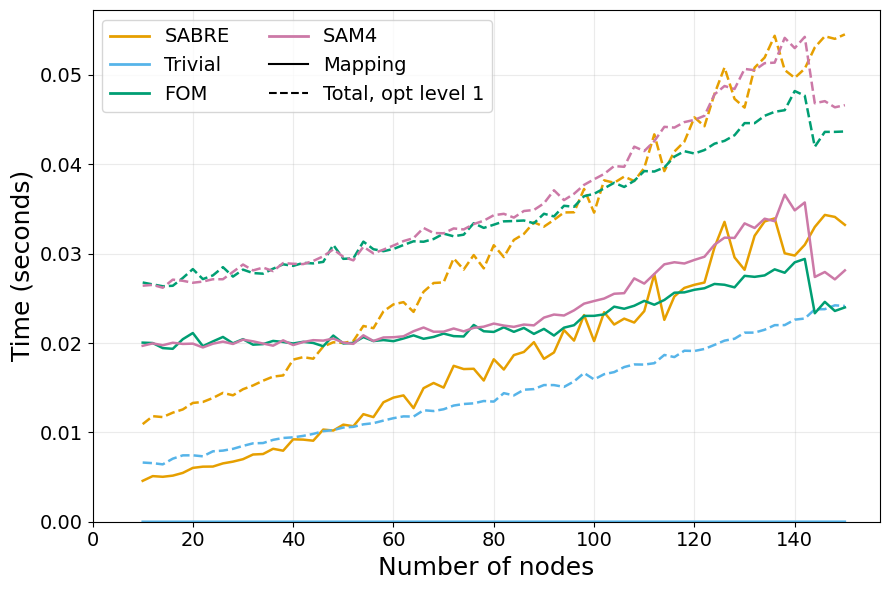

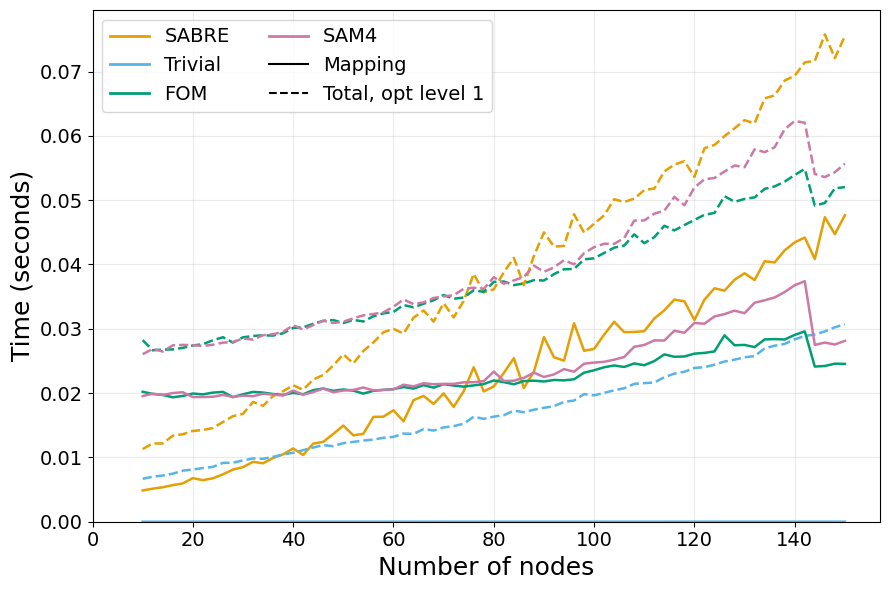

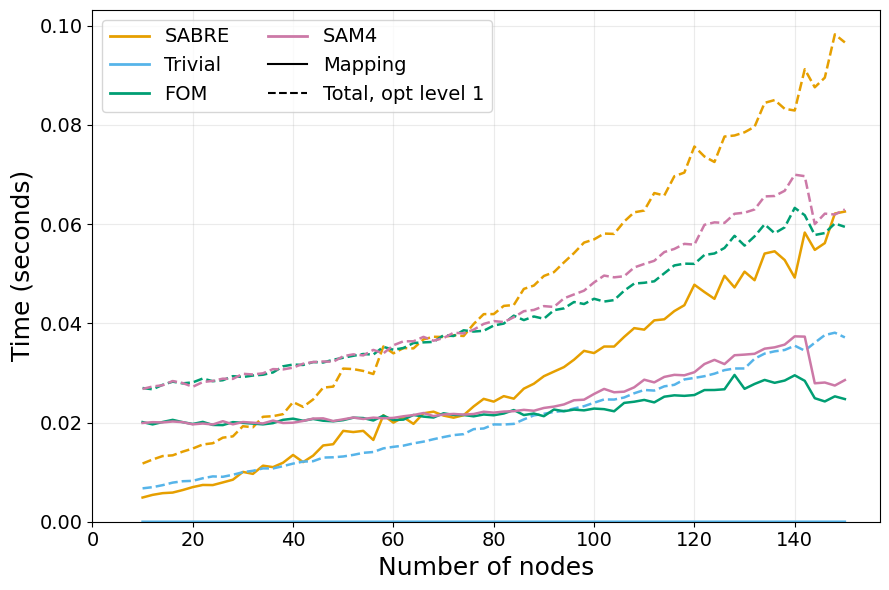

In [155]:
_plot_timing_by_parameter(
    'ba',
    'Median mapping and total compilation time, opt level 1',
    [
        ('mapping_time', None, '-', 'Mapping'),
        ('total_compilation_time', 1, '--', 'Total, opt level 1'),
    ],
    metric=1
)


### 9. Number of nodes vs median total compilation time, optimization levels 2 and 3


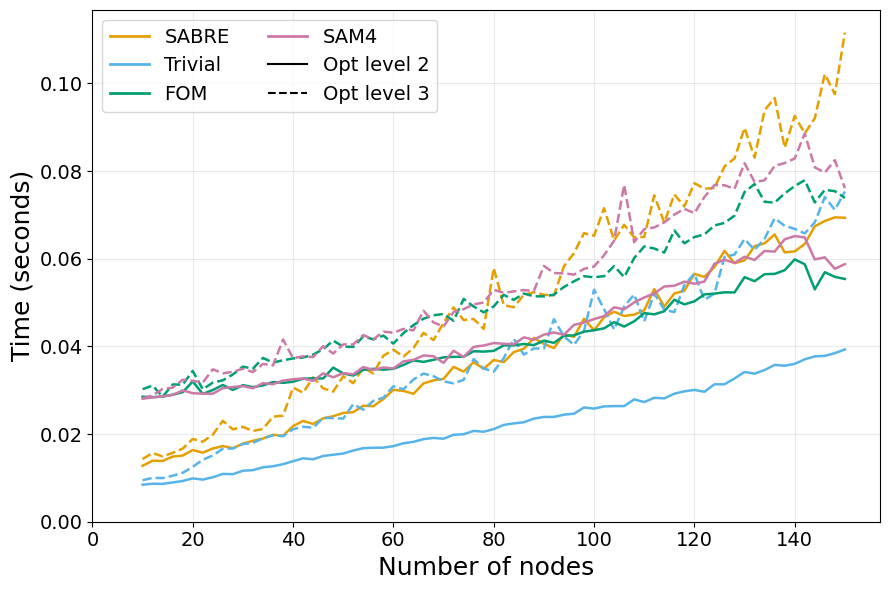

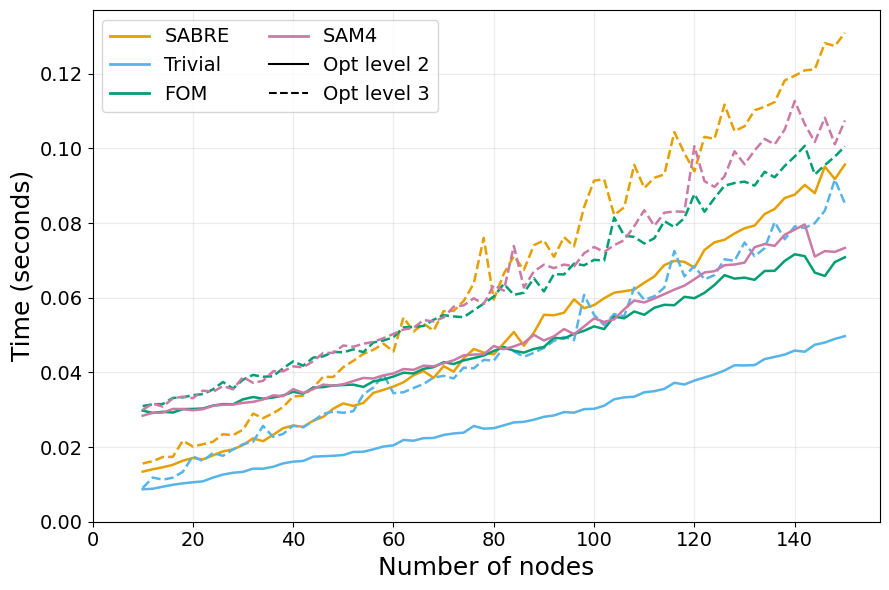

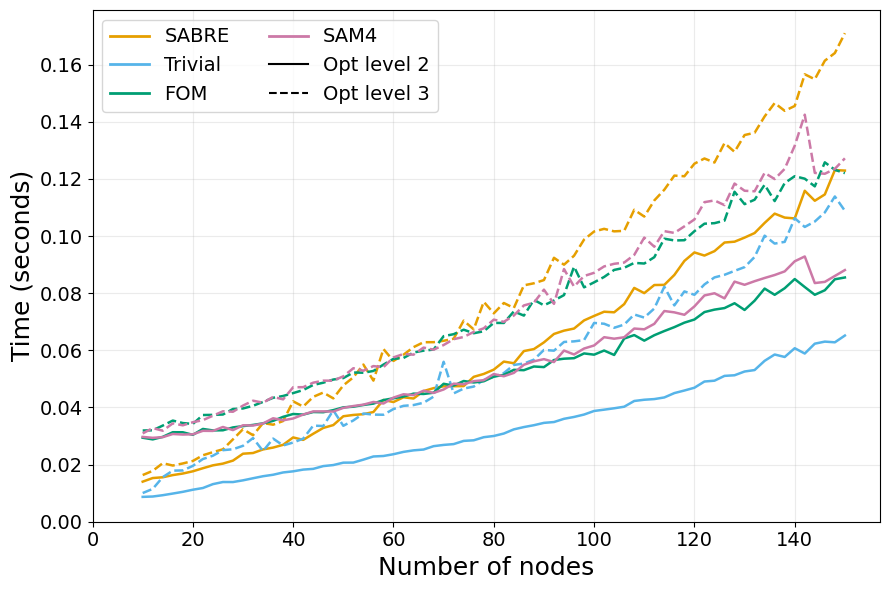

In [156]:
_plot_timing_by_parameter(
    'ba',
    'Median total compilation time, opt levels 2 and 3',
    [
        ('total_compilation_time', 2, '-', 'Opt level 2'),
        ('total_compilation_time', 3, '--', 'Opt level 3'),
    ],
    metric=2
)
